In [47]:
import os as _layout_os
from pathlib import Path as _LayoutPath
_layout_root = next(p for p in (_LayoutPath.cwd(), *_LayoutPath.cwd().parents)
                    if (p / "src" / "benchmarks.py").is_file() and (p / "scripts").is_dir())
_layout_os.chdir(_layout_root)

import os
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

In [48]:
# aggregate sampled results for multiple benchmarks
def generate_dataframe(results_dir, benchmark, model, fields, results0_dir="evaluated1/results0", position=""):
    # field0 comes from a different repo: results0/<same structure>
    path = os.path.join(
            results0_dir,
            f'{model}/{benchmark}/{benchmark}_{model}_0.json'
        )
    
    with open(path, "r") as f:
        data = json.load(f)
        
    df = pd.DataFrame(data)
    df = df.rename(columns={"score": "score0"}) # rename score into score0

    # generate a dataframe
    for af in fields[1:]:
        path = os.path.join(
            results_dir,
            f'{model}/{benchmark}/{benchmark}_{model}_{af}.json'
        )
        with open(path, "r") as f:
            data = json.load(f)
            
        df_field = pd.DataFrame(data).filter(items=['id', 'score'])
        df_field.columns=['id', f"score{af}"]
        df = df.merge(df_field, on='id', how='left')

    
    for af in fields:
        df[f"score{af}"] = pd.to_numeric(df[f"score{af}"], errors='coerce') # replace non numeric scores with NaN
        df[f"score{af}"] = df[f"score{af}"].fillna(0) # fill NaN scores with 0
        df[f"score{af}"] = df[f"score{af}"].apply(lambda x: 0 if x > 1 else x) # replace all scores > 1 with 0
        df[f"score{af}"] = df[f"score{af}"].apply(lambda x: 1 if x >= 0.7 else 0) # convert scores to binary (1 if score >= 0.7 else 0)

    return df


# aggregate sampled results for multiple benchmarks
def generate_dataframe_scaling(results_dir, benchmark, model, fields, results0_dir="evaluated1/results0", position=""):
    # field0 comes from a different repo: results0/<same structure>
    path = os.path.join(
            results0_dir,
            f'{model}/{benchmark}/{benchmark}_{model}_0.json'
        )
    
    with open(path, "r") as f:
        data = json.load(f)
        
    df = pd.DataFrame(data)
    df = df.rename(columns={"score": "score0"}) # rename score into score0

    # generate a dataframe
    for af in fields[1:]:
        path = os.path.join(
            results_dir,
            f'{model}/{benchmark}/{benchmark}_{model}_{af+1}.json'
        )
        with open(path, "r") as f:
            data = json.load(f)
            
        df_field = pd.DataFrame(data).filter(items=['id', 'score'])
        df_field.columns=['id', f"score{af}"]
        df = df.merge(df_field, on='id', how='left')

    
    for af in fields:
        df[f"score{af}"] = pd.to_numeric(df[f"score{af}"], errors='coerce') # replace non numeric scores with NaN
        df[f"score{af}"] = df[f"score{af}"].fillna(0) # fill NaN scores with 0
        df[f"score{af}"] = df[f"score{af}"].apply(lambda x: 0 if x > 1 else x) # replace all scores > 1 with 0
        df[f"score{af}"] = df[f"score{af}"].apply(lambda x: 1 if x >= 0.7 else 0) # convert scores to binary (1 if score >= 0.7 else 0)

    return df

In [49]:
def calculate_accuracies(df, fields):
    accuracies = df[[f"score{af}" for af in fields]].sum() / len(df)
    return pd.DataFrame([accuracies.values], columns = accuracies.index)

def extract_family(model_name):
    """
    Extracts a generic model family from a model name.
    Works for Qwen, LLaVA, GPT, Gemini, etc.
    """
    # Take everything before first '-' OR first digit transition
    match = re.match(r"([A-Za-z]+[\d\.]*)", model_name)
    return match.group(1) if match else model_name


def plot_model_accuracies(df):
    plt.figure(figsize=(11, 6))
    
    fields = [col for col in df.columns if col not in ["model", "family"] ]
    
    # Extract families dynamically
    df["family"] = df["model"].apply(extract_family)
    families = sorted(df["family"].unique())
    
    # Assign markers per family (scalable)
    marker_list = ['o', 's', 'D', '^', 'v', 'P', 'X', '*', '<', '>']
    family_to_marker = {
        fam: marker_list[i % len(marker_list)]
        for i, fam in enumerate(families)
    }
    
    # Colors per model
    colors = plt.cm.tab20.colors
    
    for i, (_, row) in enumerate(df.iterrows()):
        plt.plot(
            fields,
            row[fields],
            label=row["model"],
            color=colors[i % len(colors)],
            marker=family_to_marker[row["family"]],
            linewidth=2,
            markersize=6
        )
    
    # Labels
    plt.xlabel("Fields", fontsize=12)
    plt.ylabel("Accuracy", fontsize=12)
    plt.title("Model Performance Across Fields", fontsize=14)
    
    # Grid
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
    
    # X ticks
    plt.xticks(rotation=45)
    
    # Legend (models)
    plt.legend(
        title="Model",
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        fontsize=9
    )
    
    plt.tight_layout()
    plt.show()

def aggregate_dataframe(df):
    agg_df = df.groupby('id').agg({col: 'max' for col in df.columns if col.startswith('score')}).reset_index()
    return agg_df


In [50]:
def combined_df(results_path, models, benchmarks):
    #model = models[0]
    df_combined = pd.DataFrame()
    accuracies = pd.DataFrame()
    accuracies_b = pd.DataFrame()

    for model in models:
        for benchmark in benchmarks:
            df = generate_dataframe(
                results_dir = results_path,
                benchmark = benchmark,
                model = model,
                fields = fields
            )
            df = aggregate_dataframe(df)
            df["benchmark"] = benchmark
            df["model"] = model

            # Compute accuracy at each field per benchmark
            accuracy_b = calculate_accuracies(df, fields)
            accuracy_b['benchmark'] = benchmark
            accuracy_b['model'] = model
            accuracies_b = pd.concat([accuracies_b, accuracy_b])

            # combine all benchmarks
            df_combined = pd.concat([df_combined, df])

        # Compute accuracy at each field
        accuracy_m = calculate_accuracies(df_combined, fields)
        accuracy_m['model'] = model
        accuracies = pd.concat([accuracies, accuracy_m])

    return accuracies, df_combined, df

def combined_df_scaling(results_path, models, benchmarks):
    #model = models[0]
    df_combined = pd.DataFrame()
    accuracies = pd.DataFrame()
    accuracies_b = pd.DataFrame()

    for model in models:
        for benchmark in benchmarks:
            df = generate_dataframe_scaling(
                results_dir = results_path,
                benchmark = benchmark,
                model = model,
                fields = fields
            )
            df = aggregate_dataframe(df)
            df["benchmark"] = benchmark
            df["model"] = model

            # Compute accuracy at each field per benchmark
            accuracy_b = calculate_accuracies(df, fields)
            accuracy_b['benchmark'] = benchmark
            accuracy_b['model'] = model
            accuracies_b = pd.concat([accuracies_b, accuracy_b])

            # combine all benchmarks
            df_combined = pd.concat([df_combined, df])

        # Compute accuracy at each field
        accuracy_m = calculate_accuracies(df_combined, fields)
        accuracy_m['model'] = model
        accuracies = pd.concat([accuracies, accuracy_m])

    return accuracies, df_combined, df

In [51]:
def plot_model_accuracies(df1, df2, df3, df4, df5, 
                          titles=("Subplot 1", "Subplot 2", "Subplot 3")):
    
    # Set publication-quality style
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'DejaVu Serif'],
        'font.size': 18,
        'axes.labelsize': 18,
        'axes.titlesize': 13,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'legend.fontsize': 14,
        'figure.dpi': 300,
        'savefig.dpi': 300,
        'savefig.bbox': 'tight',
        'axes.linewidth': 1.2,
        'grid.linewidth': 0.5,
        'lines.linewidth': 1,
        'lines.markersize': 7,
    })
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    
    # Prepare dataframes
    dfs = [df1, df2, df3, df4, df5]
    df1, df2, df3, df4, df5 = [d.copy() for d in dfs]
    for df in [df1, df2, df3, df4, df5]:
        df["family"] = df["model"].apply(extract_family)
    
    # Collect all models and families
    all_models = list(df1["model"])
    for df in [df2, df3, df4, df5]:
        for m in df["model"]:
            if m not in all_models:
                all_models.append(m)
    
    all_families = sorted(set().union(*[set(df["family"].unique()) 
                                        for df in [df1, df2, df3, df4, df5]]))
    
    # Professional color palette (colorblind-friendly)
    color_palette = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
        '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf',
        '#aec7e8', '#ffbb78', '#98df8a', '#ff9896', '#c5b0d5',
        '#c49c94', '#f7b6d2', '#c7c7c7', '#dbdb8d', '#9edae5'
    ]
    
    # Distinct markers for families
    marker_list = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', '<', '>']
    family_to_marker = {fam: marker_list[i % len(marker_list)] 
                        for i, fam in enumerate(all_families)}
    
    # Assign colors to models
    model_to_color = {model: color_palette[i % len(color_palette)] 
                      for i, model in enumerate(all_models)}
    
    def plot_on_ax(ax, df_solid, df_dashed=None, title="", is_first=False, is_last=False):
        solid_fields = [col for col in df_solid.columns 
                       if col not in ["model", "family"]]
        
        # Plot solid lines
        for _, row in df_solid.iterrows():
            ax.plot(
                solid_fields,
                row[solid_fields],
                color=model_to_color[row["model"]],
                marker=family_to_marker[row["family"]],
                linewidth=1,
                markersize=7,
                linestyle="-",
                markeredgewidth=0.5,
                markeredgecolor='white',
                alpha=0.9,
                zorder=3
            )
        
        # Plot dashed lines
        if df_dashed is not None:
            dashed_fields = [col for col in df_dashed.columns 
                           if col not in ["model", "family"]]
            for _, row in df_dashed.iterrows():
                ax.plot(
                    dashed_fields,
                    row[dashed_fields],
                    color=model_to_color[row["model"]],
                    marker=family_to_marker[row["family"]],
                    linewidth=1,
                    markersize=7,
                    linestyle="--",
                    markeredgewidth=0.5,
                    markeredgecolor='white',
                    alpha=0.9,
                    zorder=3
                )
        
        # Styling
        ax.set_title(title, fontsize=14, fontweight='semibold', pad=12)
        #ax.set_xlabel("Fields", fontsize=12, fontweight='medium')
        
        # Grid
        ax.grid(True, linestyle='-', linewidth=0.3, alpha=0.3, color='gray', zorder=1)
        ax.grid(True, which='minor', linestyle=':', linewidth=0.2, alpha=0.2, color='gray', zorder=1)
        ax.minorticks_on()
        
        # Spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.2)
        ax.spines['bottom'].set_linewidth(1.2)
        
        # X-axis
        ax.tick_params(axis='x', rotation=30, labelsize=12)
        ax.tick_params(axis='both', which='major', length=5, width=1.2)
        ax.tick_params(axis='both', which='minor', length=3, width=0.8)
        
        
        # Background
        ax.set_facecolor('#FAFAFA')
    
    # Plot subplots
    plot_on_ax(axes[0], df1, df2, title=titles[0], is_first=True)
    plot_on_ax(axes[1], df3, df4, title=titles[1])
    plot_on_ax(axes[2], df5, None, title=titles[2], is_last=True)
    
    # Y-axis label
    axes[0].set_ylabel("Accuracy", fontsize=12, fontweight='medium')
    #axes[1].set_ylabel("Accuracy", fontsize=12, fontweight='medium')
    #axes[2].set_ylabel("Accuracy", fontsize=12, fontweight='medium')
    for ax in axes:
        ax.tick_params(labelleft=True)
    
    # Build legends with better styling
    from matplotlib.lines import Line2D
    
    # Model legend
    model_handles = [
        Line2D([0], [0], 
               color=model_to_color[m], 
               marker=family_to_marker[extract_family(m)],
               linewidth=2.5, 
               markersize=7, 
               linestyle='-',
               markeredgewidth=0.5,
               markeredgecolor='white',
               label=m)
        for m in all_models
    ]
    
    # Linestyle legend
    style_handles = [
        Line2D([0], [0], color='#555555', linewidth=2.5, linestyle='-', label='Center'),
        Line2D([0], [0], color='#555555', linewidth=2.5, linestyle='--', label='Tokenization Origin'),
    ]
    
    # Position legends outside the plot area
    legend1 = fig.legend(
        handles=model_handles,
        title="Model",
        bbox_to_anchor=(0.99, 0.65),
        loc='center left',
        fontsize=12,
        title_fontsize=12,
        frameon=True,
        fancybox=False,
        shadow=False,
        framealpha=0.95,
        edgecolor='#CCCCCC',
        facecolor='white'
    )
    
    legend2 = fig.legend(
        handles=style_handles,
        title="Position",
        bbox_to_anchor=(0.99, 0.25),
        loc='center left',
        fontsize=12,
        title_fontsize=12,
        frameon=True,
        fancybox=False,
        shadow=False,
        framealpha=0.95,
        edgecolor='#CCCCCC',
        facecolor='white'
    )
    
    # Keep both legends
    fig.add_artist(legend1)
    
    # Adjust layout
    plt.tight_layout()
    plt.subplots_adjust(right=0.98, wspace=0.08)
    
    # Save with high quality
    # plt.savefig('model_accuracies.pdf', format='pdf', bbox_inches='tight')
    plt.savefig('model_accuracies.png', format='png', bbox_inches='tight', dpi=300)
    
    plt.show()
    
    # Reset to default style after plotting
    plt.rcParams.update(plt.rcParamsDefault)

In [52]:
fields = [0,0.5,1,2,3,4,5]

results_path_2d_center = "evaluated1/results_field_center_aspect"
results_path_2d_start = "evaluated/results_field_urc_aspect"
results_path_1d_center = "evaluated1/results_field"
results_path_1d_start = "evaluated1/results_field_upper_right_corner"
results_path_interpolation = "evaluated1/results_interpolation"

benchmarks = [
    "CharXiv",
    "MathVerse",
    "MMEval",
    "MMStar",
    "MMVet"
]

models = [#'Qwen2-VL-72B-Instruct',
 #'Qwen2.5-VL-32B-Instruct',
 'Qwen2-VL-7B-Instruct',
 'Qwen2.5-VL-3B-Instruct',
 'Qwen3-VL-2B-Instruct',
 'Qwen3-VL-4B-Instruct',
 'Qwen2-VL-2B-Instruct',
 #'Qwen2.5-VL-72B-Instruct',
 'Qwen2.5-VL-7B-Instruct',
 #'Qwen3-VL-32B-Instruct',
 'Qwen3-VL-8B-Instruct',
 'Llama-3.2-11B-Vision-Instruct',
 'llava-1.5-7b-hf',
 'pixtral-12b',
 #"gpt-5-mini"
 ]

In [53]:
accuracies1, df_combined1, df1 = combined_df(results_path_2d_center, models, benchmarks)
accuracies2, df_combined2, df2 = combined_df(results_path_2d_start, models, benchmarks)

accuracies3, df_combined3, df3 = combined_df(results_path_1d_center, models, benchmarks)
accuracies4, df_combined4, df4 = combined_df(results_path_1d_start, models, benchmarks)

accuracies5, df_combined5, df5 = combined_df_scaling(results_path_interpolation, models, benchmarks)

In [54]:
accuracies1.columns = ["Original", "150%", "200%", "300%", "400%", "500%", "600%", "model"]
accuracies2.columns = ["Original", "150%", "200%", "300%", "400%", "500%", "600%", "model"]
accuracies3.columns = ["Original", "150%", "200%", "300%", "400%", "500%", "600%", "model"]
accuracies4.columns = ["Original", "150%", "200%", "300%", "400%", "500%", "600%", "model"]
accuracies5.columns = ["Original", "150%", "200%", "300%", "400%", "500%", "600%", "model"]

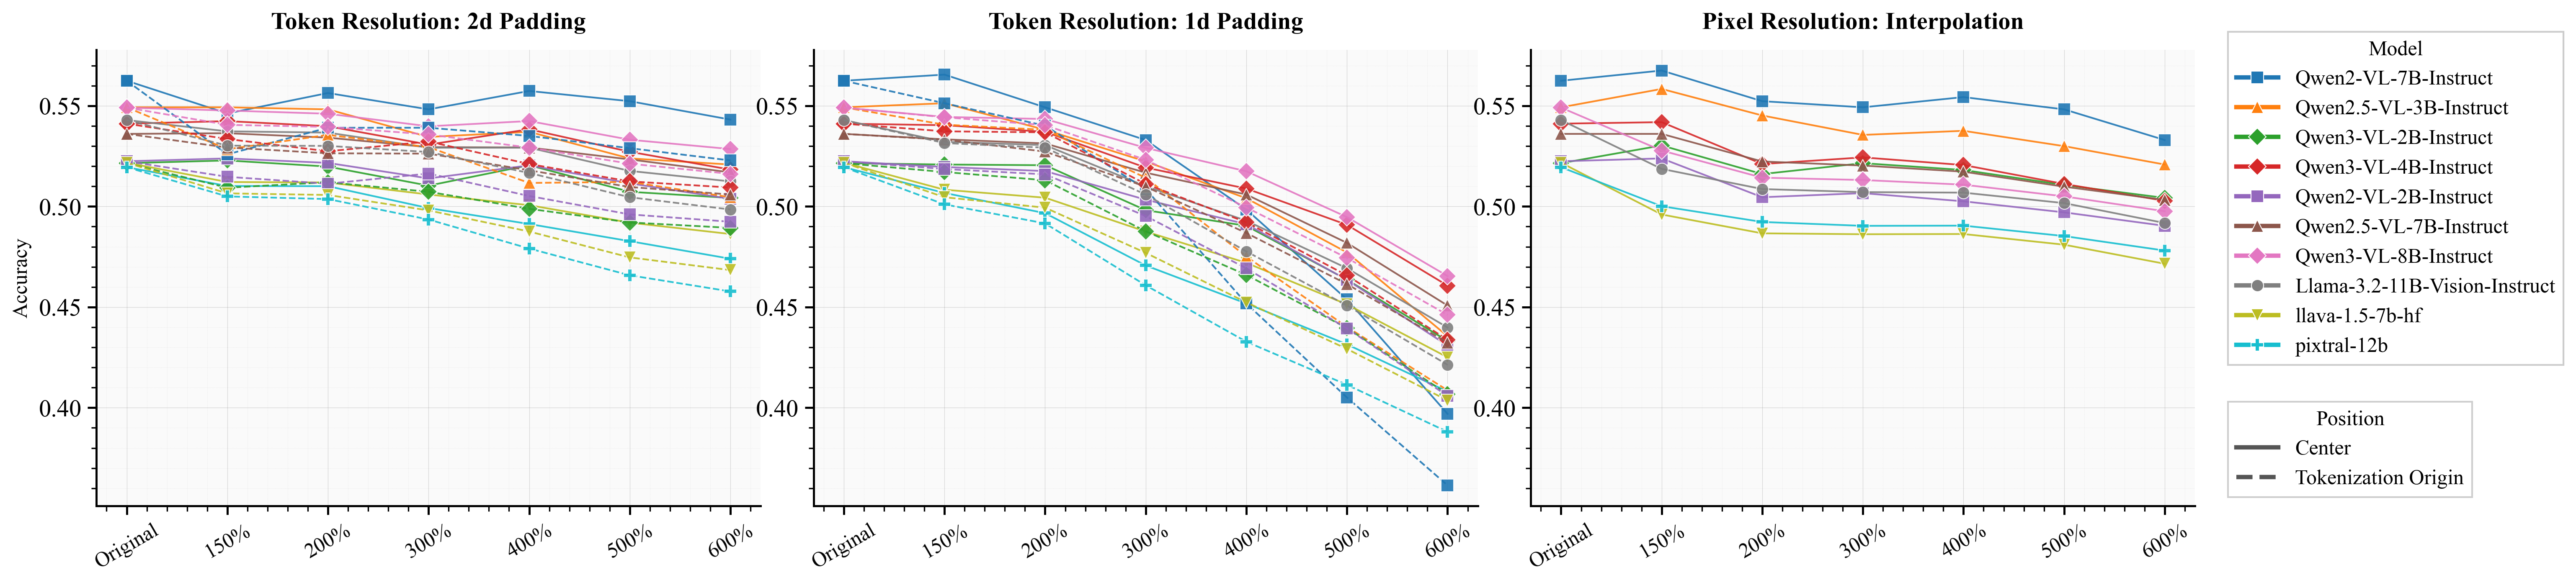

In [55]:
plot_model_accuracies(accuracies1, accuracies2, accuracies3, accuracies4, accuracies5, 
                      titles=("Token Resolution: 2d Padding", "Token Resolution: 1d Padding", "Pixel Resolution: Interpolation"))

# Table for all augmentations

In [56]:
import pandas as pd
import numpy as np

def compute_metrics(df, models, fields):
    rows = []

    for model in models:
        m_df = df[df['model'] == model]

        m_correct = m_df[m_df["score0"] == 1]
        m_wrong   = m_df[m_df["score0"] == 0]

        # ----- Decay -----
        if len(m_correct) > 0:
            decay = m_correct[[f"score{af}" for af in fields]].mean()
        else:
            decay = pd.Series(
                [0] * len(fields),
                index=[f"score{af}" for af in fields]
            )

        # ----- Recovery / PVS -----
        if len(m_wrong) > 0:
            recovery = m_wrong[[f"score{af}" for af in fields]].mean()

            # PVS-style recovery:
            overall_recovery = (
                (m_wrong[[f"score{af}" for af in fields]] == 1)
                .any(axis=1)
                .mean()
            )
        else:
            recovery = pd.Series(
                [0] * len(fields),
                index=[f"score{af}" for af in fields]
            )
            overall_recovery = 0

        # Rename
        decay.index = [f"decay{af}" for af in fields]
        recovery.index = [f"recovery{af}" for af in fields]

        row = pd.concat([decay, recovery])

        row["PVS"] = overall_recovery
        row["model"] = model

        rows.append(row)

    results = pd.DataFrame(rows)

    # ----- AUSC -----
    decay_cols = [f"decay{af}" for af in fields]

    x = np.array(fields)
    dx = np.diff(x)

    def compute_ausc(row):
        y = row[decay_cols].values.astype(float)
        area = np.sum(dx * (y[:-1] + y[1:]) / 2)
        return area / np.sum(dx)

    results["AUSC"] = results.apply(compute_ausc, axis=1)

    return results

In [57]:
augmentation_dfs = {
    "2d padding (center)": df_combined1,
    "2d padding (tokenization origin)": df_combined2,
    "1d padding (center)": df_combined3,
    "1d padding (tokenization origin)": df_combined4,
    "intrapolation": df_combined5,
}

In [58]:
all_results = []

for aug_name, aug_df in augmentation_dfs.items():

    metrics = compute_metrics(
        df=aug_df,
        models=models,
        fields=fields
    )

    summary = metrics[["model", "AUSC", "PVS"]].copy()
    summary["augmentation"] = aug_name

    all_results.append(summary)

final_table = pd.concat(all_results, ignore_index=True)

print(final_table)

                            model      AUSC       PVS  \
0            Qwen2-VL-7B-Instruct  0.850451  0.352668   
1          Qwen2.5-VL-3B-Instruct  0.832197  0.361050   
2            Qwen3-VL-2B-Instruct  0.826797  0.416350   
3            Qwen3-VL-4B-Instruct  0.854822  0.474619   
4            Qwen2-VL-2B-Instruct  0.844558  0.290441   
5          Qwen2.5-VL-7B-Instruct  0.870336  0.358974   
6            Qwen3-VL-8B-Instruct  0.866343  0.414169   
7   Llama-3.2-11B-Vision-Instruct  0.718598  0.476673   
8                 llava-1.5-7b-hf  0.673487  0.365204   
9                     pixtral-12b  0.706809  0.421907   
10           Qwen2-VL-7B-Instruct  0.829693  0.348028   
11         Qwen2.5-VL-3B-Instruct  0.822917  0.319475   
12           Qwen3-VL-2B-Instruct  0.817102  0.393536   
13           Qwen3-VL-4B-Instruct  0.850761  0.454315   
14           Qwen2-VL-2B-Instruct  0.826077  0.306985   
15         Qwen2.5-VL-7B-Instruct  0.863613  0.351282   
16           Qwen3-VL-8B-Instru

In [59]:
paper_table = final_table.pivot(
    index="model",
    columns="augmentation",
    values=["AUSC", "PVS"]
)
paper_table

AUSC  \
augmentation                  1d padding (center)   
model                                               
Llama-3.2-11B-Vision-Instruct            0.569106   
Qwen2-VL-2B-Instruct                     0.752494   
Qwen2-VL-7B-Instruct                     0.785921   
Qwen2.5-VL-3B-Instruct                   0.830019   
Qwen2.5-VL-7B-Instruct                   0.857647   
Qwen3-VL-2B-Instruct                     0.802505   
Qwen3-VL-4B-Instruct                     0.835618   
Qwen3-VL-8B-Instruct                     0.842476   
llava-1.5-7b-hf                          0.722767   
pixtral-12b                              0.520833   

                                                                \
augmentation                  1d padding (tokenization origin)   
model                                                            
Llama-3.2-11B-Vision-Instruct                         0.577947   
Qwen2-VL-2B-Instruct                                  0.715760   
Qwen2-VL-7B-Instruct                                  0.733032   
Qwen2.5-VL-3B-Instruct                                0.813731   
Qwen2.5-VL-7B-Instruct                                0.852773   
Qwen3-VL-2B-Instruct                                  0.799129   
Qwen3-VL-4B-Instruct                                  0.820474   
Qwen3-VL-8B-Instruct                                  0.832120   
llava-1.5-7b-hf                                       0.588905   
pixtral-12b                                           0.507215   

                                                   \
augmentation                  2d padding (center)   
model                                               
Llama-3.2-11B-Vision-Instruct            0.718598   
Qwen2-VL-2B-Instruct                     0.844558   
Qwen2-VL-7B-Instruct                     0.850451   
Qwen2.5-VL-3B-Instruct                   0.832197   
Qwen2.5-VL-7B-Instruct                   0.870336   
Qwen3-VL-2B-Instruct                     0.826797   
Qwen3-VL-4B-Instruct                     0.854822   
Qwen3-VL-8B-Instruct                     0.866343   
llava-1.5-7b-hf                          0.673487   
pixtral-12b                              0.706809   

                                                                              \
augmentation                  2d padding (tokenization origin) intrapolation   
model                                                                          
Llama-3.2-11B-Vision-Instruct                         0.704370      0.776931   
Qwen2-VL-2B-Instruct                                  0.826077      0.826757   
Qwen2-VL-7B-Instruct                                  0.829693      0.851083   
Qwen2.5-VL-3B-Instruct                                0.822917      0.846212   
Qwen2.5-VL-7B-Instruct                                0.863613      0.871008   
Qwen3-VL-2B-Instruct                                  0.817102      0.835512   
Qwen3-VL-4B-Instruct                                  0.850761      0.775465   
Qwen3-VL-8B-Instruct                                  0.858091      0.682767   
llava-1.5-7b-hf                                       0.592651      0.750576   
pixtral-12b                                           0.694004      0.889533   

                                              PVS  \
augmentation                  1d padding (center)   
model                                               
Llama-3.2-11B-Vision-Instruct            0.492901   
Qwen2-VL-2B-Instruct                     0.367647   
Qwen2-VL-7B-Instruct                     0.385151   
Qwen2.5-VL-3B-Instruct                   0.367615   
Qwen2.5-VL-7B-Instruct                   0.382051   
Qwen3-VL-2B-Instruct                     0.414449   
Qwen3-VL-4B-Instruct                     0.454315   
Qwen3-VL-8B-Instruct                     0.427793   
llava-1.5-7b-hf                          0.307210   
pixtral-12b                              0.432049   

                                                                \
augmentat

In [60]:
import pandas as pd
import numpy as np

def compute_metrics(df, models, fields):
    non_original_fields = fields[1:]
    rows = []

    for model in models:
        m_df = df[df['model'] == model]

        # Original accuracy
        original_acc = m_df["score0"].mean()

        m_correct = m_df[m_df["score0"] == 1]
        m_wrong   = m_df[m_df["score0"] == 0]

        # ----- Decay -----
        if len(m_correct) > 0:
            decay = m_correct[[f"score{af}" for af in fields]].mean()
        else:
            decay = pd.Series(
                [0] * len(fields),
                index=[f"score{af}" for af in fields]
            )

        # ----- Recovery / PVS -----
        if len(m_wrong) > 0:
            recovery = m_wrong[[f"score{af}" for af in fields]].mean()

            overall_recovery = (
                (m_wrong[[f"score{af}" for af in fields]] == 1)
                .any(axis=1)
                .mean()
            )
        else:
            recovery = pd.Series(
                [0] * len(fields),
                index=[f"score{af}" for af in fields]
            )
            overall_recovery = 0

        # ----- ACE / RCE: total variation of the overall accuracy curve across levels -----
        acc_curve = m_df[[f"score{af}" for af in fields]].mean()
        ace = np.sum(np.abs(np.diff(acc_curve.values)))
        acc_avg = acc_curve.mean()
        rce = ace / acc_avg if acc_avg > 0 else np.nan

        # ----- Flip+ / Flip-: correct<->wrong transitions relative to the original, per level -----
        flip_plus = {
            af: ((m_df["score0"] == 1) & (m_df[f"score{af}"] == 0)).mean()
            for af in non_original_fields
        }
        flip_minus = {
            af: ((m_df["score0"] == 0) & (m_df[f"score{af}"] == 1)).mean()
            for af in non_original_fields
        }

        # Rename
        decay.index = [f"decay{af}" for af in fields]
        recovery.index = [f"recovery{af}" for af in fields]

        row = pd.concat([decay, recovery])

        row["A0"] = original_acc
        row["PVS"] = overall_recovery
        row["ACE"] = ace
        row["RCE"] = rce
        row["Flip+_avg"] = np.mean(list(flip_plus.values()))
        row["Flip-_avg"] = np.mean(list(flip_minus.values()))
        for af in non_original_fields:
            row[f"Flip+_{af}"] = flip_plus[af]
            row[f"Flip-_{af}"] = flip_minus[af]
        row["model"] = model

        rows.append(row)

    results = pd.DataFrame(rows)

    # ----- AUSC -----
    decay_cols = [f"decay{af}" for af in fields]

    x = np.array(fields)
    dx = np.diff(x)

    def compute_ausc(row):
        y = row[decay_cols].values.astype(float)
        area = np.sum(dx * (y[:-1] + y[1:]) / 2)
        return area / np.sum(dx)

    results["AUSC"] = results.apply(compute_ausc, axis=1)

    return results

In [61]:
augmentation_dfs = {
    "2d padding (center)": df_combined1,
    "2d padding (tokenization origin)": df_combined2,
    "1d padding (center)": df_combined3,
    "1d padding (tokenization origin)": df_combined4,
    "intrapolation": df_combined5,
}

SUMMARY_COLS = ["model", "A0", "AUSC", "PVS", "ACE", "RCE", "Flip+_avg", "Flip-_avg"]

all_results = []
all_flip_levels = []

for aug_name, aug_df in augmentation_dfs.items():

    metrics = compute_metrics(
        df=aug_df,
        models=models,
        fields=fields
    )

    summary = metrics[SUMMARY_COLS].copy()
    summary["augmentation"] = aug_name
    all_results.append(summary)

    # Per-level Flip+ / Flip- (tidy format, kept separate from the scalar summary above)
    level_flip_cols = [c for c in metrics.columns
                       if (c.startswith("Flip+_") or c.startswith("Flip-_"))
                       and c not in ("Flip+_avg", "Flip-_avg")]
    flip_long = metrics[["model"] + level_flip_cols].melt(
        id_vars="model", var_name="metric_level", value_name="value"
    )
    flip_long[["metric", "level"]] = flip_long["metric_level"].str.rsplit("_", n=1, expand=True)
    flip_long["level"] = flip_long["level"].astype(float)
    flip_long["augmentation"] = aug_name
    all_flip_levels.append(flip_long.drop(columns="metric_level"))

final_table = pd.concat(all_results, ignore_index=True)
flip_table_by_level = pd.concat(all_flip_levels, ignore_index=True).pivot_table(
    index=["model", "augmentation", "level"], columns="metric", values="value"
).reset_index()

final_table

,model,A0,AUSC,PVS,ACE,RCE,Flip+_avg,Flip-_avg,augmentation
0,Qwen2-VL-7B-Instruct,0.562437,0.850451,0.352668,0.057868,0.104779,0.086971,0.075127,2d padding (center)
1,Qwen2.5-VL-3B-Instruct,0.536041,0.832197,0.361050,0.076142,0.145631,0.093232,0.077834,2d padding (center)
2,Qwen3-VL-2B-Instruct,0.465990,0.826797,0.416350,0.053807,0.114365,0.085110,0.090355,2d padding (center)
3,Qwen3-VL-4B-Instruct,0.600000,0.854822,0.474619,0.041624,0.070516,0.092724,0.081387,2d padding (center)
4,Qwen2-VL-2B-Instruct,0.447716,0.844558,0.290441,0.010152,0.022661,0.073435,0.073773,2d padding (center)
5,Qwen2.5-VL-7B-Instruct,0.604061,0.870336,0.358974,0.059898,0.101126,0.080711,0.067005,2d padding (center)
6,Qwen3-VL-8B-Instruct,0.627411,0.866343,0.414169,0.084264,0.138038,0.087817,0.068020,2d padding (center)
7,Llama-3.2-11B-Vision-Instruct,0.499492,0.718598,0.476673,0.111675,0.249272,0.146701,0.086633,2d padding (center)
8,llava-1.5-7b-hf,0.352284,0.673487,0.365204,0.121827,0.400000,0.120305,0.064636,2d padding (center)
9,pixtral-12b,0.499492,0.706809,0.421907,0.138071,0.312336,0.151946,0.084941,2d padding (center)


In [62]:
paper_table = final_table.pivot(
    index="model",
    columns="augmentation",
    values=["AUSC", "PVS", "ACE", "RCE", "Flip+_avg", "Flip-_avg"]
)

# Add original accuracy once
paper_table[("A0", "base")] = (
    final_table.drop_duplicates("model")
    .set_index("model")["A0"]
)

paper_table

AUSC  \
augmentation                  1d padding (center)   
model                                               
Llama-3.2-11B-Vision-Instruct            0.569106   
Qwen2-VL-2B-Instruct                     0.752494   
Qwen2-VL-7B-Instruct                     0.785921   
Qwen2.5-VL-3B-Instruct                   0.830019   
Qwen2.5-VL-7B-Instruct                   0.857647   
Qwen3-VL-2B-Instruct                     0.802505   
Qwen3-VL-4B-Instruct                     0.835618   
Qwen3-VL-8B-Instruct                     0.842476   
llava-1.5-7b-hf                          0.722767   
pixtral-12b                              0.520833   

                                                                \
augmentation                  1d padding (tokenization origin)   
model                                                            
Llama-3.2-11B-Vision-Instruct                         0.577947   
Qwen2-VL-2B-Instruct                                  0.715760   
Qwen2-VL-7B-Instruct                                  0.733032   
Qwen2.5-VL-3B-Instruct                                0.813731   
Qwen2.5-VL-7B-Instruct                                0.852773   
Qwen3-VL-2B-Instruct                                  0.799129   
Qwen3-VL-4B-Instruct                                  0.820474   
Qwen3-VL-8B-Instruct                                  0.832120   
llava-1.5-7b-hf                                       0.588905   
pixtral-12b                                           0.507215   

                                                   \
augmentation                  2d padding (center)   
model                                               
Llama-3.2-11B-Vision-Instruct            0.718598   
Qwen2-VL-2B-Instruct                     0.844558   
Qwen2-VL-7B-Instruct                     0.850451   
Qwen2.5-VL-3B-Instruct                   0.832197   
Qwen2.5-VL-7B-Instruct                   0.870336   
Qwen3-VL-2B-Instruct                     0.826797   
Qwen3-VL-4B-Instruct                     0.854822   
Qwen3-VL-8B-Instruct                     0.866343   
llava-1.5-7b-hf                          0.673487   
pixtral-12b                              0.706809   

                                                                              \
augmentation                  2d padding (tokenization origin) intrapolation   
model                                                                          
Llama-3.2-11B-Vision-Instruct                         0.704370      0.776931   
Qwen2-VL-2B-Instruct                                  0.826077      0.826757   
Qwen2-VL-7B-Instruct                                  0.829693      0.851083   
Qwen2.5-VL-3B-Instruct                                0.822917      0.846212   
Qwen2.5-VL-7B-Instruct                                0.863613      0.871008   
Qwen3-VL-2B-Instruct                                  0.817102      0.835512   
Qwen3-VL-4B-Instruct                                  0.850761      0.775465   
Qwen3-VL-8B-Instruct                                  0.858091      0.682767   
llava-1.5-7b-hf                                       0.592651      0.750576   
pixtral-12b                                           0.694004      0.889533   

                                              PVS  \
augmentation                  1d padding (center)   
model                                               
Llama-3.2-11B-Vision-Instruct            0.492901   
Qwen2-VL-2B-Instruct                     0.367647   
Qwen2-VL-7B-Instruct                     0.385151   
Qwen2.5-VL-3B-Instruct                   0.367615   
Qwen2.5-VL-7B-Instruct                   0.382051   
Qwen3-VL-2B-Instruct                     0.414449   
Qwen3-VL-4B-Instruct                     0.454315   
Qwen3-VL-8B-Instruct                     0.427793   
llava-1.5-7b-hf                          0.307210   
pixtral-12b                              0.432049   

                                                                \
augmentat

### Per-level Flip+ / Flip- (averaged across augmentations)

In [63]:
flip_level_summary = (
    flip_table_by_level
    .groupby(["model", "level"], observed=True)[["Flip+", "Flip-"]]
    .mean()
    .reset_index()
)

flip_plus_by_level = flip_level_summary.pivot(index="model", columns="level", values="Flip+")
flip_minus_by_level = flip_level_summary.pivot(index="model", columns="level", values="Flip-")

flip_plus_by_level

level,0.5,1.0,2.0,3.0,4.0,5.0
model,,,,,,
Llama-3.2-11B-Vision-Instruct,0.126497,0.129137,0.155939,0.187614,0.207310,0.229442
Qwen2-VL-2B-Instruct,0.070051,0.077360,0.084467,0.101320,0.117360,0.133807
Qwen2-VL-7B-Instruct,0.068629,0.081218,0.099695,0.116548,0.141726,0.162030
Qwen2.5-VL-3B-Instruct,0.064162,0.072690,0.085685,0.104365,0.116548,0.130152
Qwen2.5-VL-7B-Instruct,0.059492,0.065178,0.082640,0.095025,0.102741,0.109036
Qwen3-VL-2B-Instruct,0.077766,0.078376,0.088528,0.090152,0.099289,0.105178
Qwen3-VL-4B-Instruct,0.083452,0.096041,0.099898,0.111066,0.123249,0.139492
Qwen3-VL-8B-Instruct,0.104975,0.104569,0.117970,0.119797,0.134822,0.145178
llava-1.5-7b-hf,0.101320,0.114721,0.122030,0.128934,0.134010,0.134416


In [64]:
flip_minus_by_level

level,0.5,1.0,2.0,3.0,4.0,5.0
model,,,,,,
Llama-3.2-11B-Vision-Instruct,0.080000,0.088528,0.085888,0.086091,0.078173,0.076751
Qwen2-VL-2B-Instruct,0.066599,0.070863,0.077970,0.077360,0.071269,0.069442
Qwen2-VL-7B-Instruct,0.057462,0.066193,0.072893,0.073503,0.076954,0.071066
Qwen2.5-VL-3B-Instruct,0.068020,0.071269,0.068426,0.075127,0.076142,0.078782
Qwen2.5-VL-7B-Instruct,0.056650,0.059898,0.066193,0.071066,0.074518,0.072690
Qwen3-VL-2B-Instruct,0.080812,0.079188,0.083046,0.094213,0.087919,0.085685
Qwen3-VL-4B-Instruct,0.079594,0.076954,0.079188,0.079594,0.081218,0.076751
Qwen3-VL-8B-Instruct,0.062335,0.064569,0.064772,0.062944,0.063959,0.062132
llava-1.5-7b-hf,0.058883,0.060711,0.061320,0.057259,0.062132,0.058680


### Model leaderboard: Acc_orig, AUSC, PVS, ACE, RCE, Flip+, Flip-

In [65]:
leaderboard = (
    final_table
    .groupby("model")[["A0", "AUSC", "PVS", "ACE", "RCE", "Flip+_avg", "Flip-_avg"]]
    .mean()
    .rename(columns={"A0": "Acc_orig", "Flip+_avg": "Flip+", "Flip-_avg": "Flip-"})
    .sort_values("AUSC", ascending=False)
)

leaderboard

,Acc_orig,AUSC,PVS,ACE,RCE,Flip+,Flip-
model,,,,,,,
Qwen2.5-VL-7B-Instruct,0.604061,0.863076,0.367692,0.053807,0.091466,0.085685,0.066836
Qwen2.5-VL-3B-Instruct,0.536041,0.829015,0.350547,0.070457,0.136626,0.095601,0.072961
Qwen3-VL-4B-Instruct,0.600000,0.827428,0.457360,0.086294,0.151006,0.108866,0.078883
Qwen3-VL-8B-Instruct,0.627411,0.816359,0.407629,0.109036,0.195372,0.121218,0.063452
Qwen3-VL-2B-Instruct,0.465990,0.816209,0.409125,0.080000,0.173987,0.089882,0.085144
Qwen2-VL-7B-Instruct,0.562437,0.810036,0.363341,0.109239,0.214308,0.111641,0.069679
Qwen2-VL-2B-Instruct,0.447716,0.793129,0.326471,0.078173,0.190790,0.097394,0.072250
Llama-3.2-11B-Vision-Instruct,0.499492,0.669390,0.476673,0.173401,0.429167,0.172657,0.082572
llava-1.5-7b-hf,0.352284,0.665677,0.325705,0.102132,0.347939,0.122572,0.059831


### Why do AUSC and PVS diverge?

Pearson r(AUSC, PVS): -0.20 across models (averaged), -0.29 across all (model, augmentation) rows


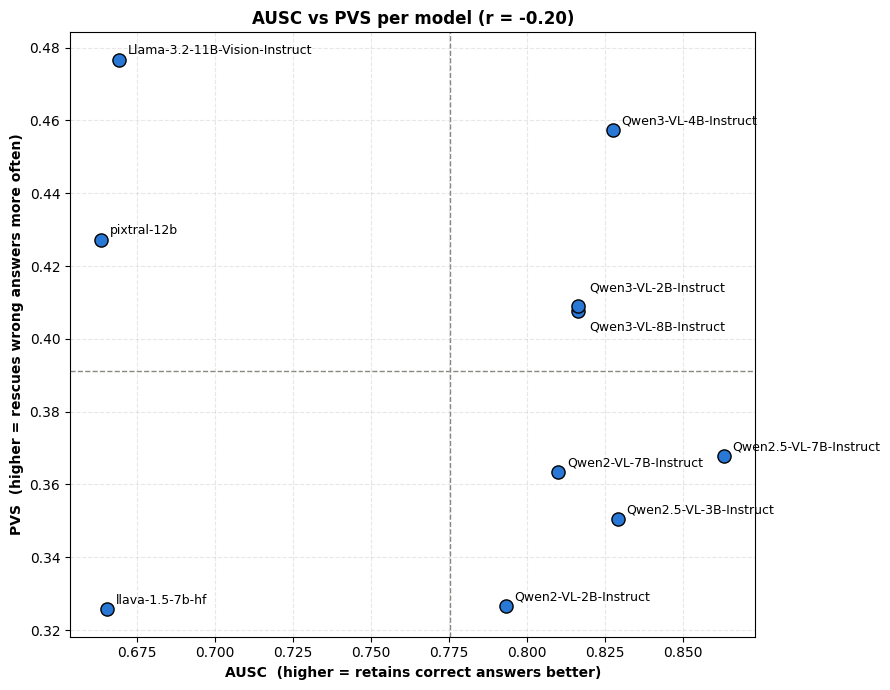

In [66]:
r = leaderboard["AUSC"].corr(leaderboard["PVS"])
r_all = final_table["AUSC"].corr(final_table["PVS"])
print(f"Pearson r(AUSC, PVS): {r:.2f} across models (averaged), {r_all:.2f} across all (model, augmentation) rows")

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(leaderboard["AUSC"], leaderboard["PVS"], s=90, color="#2a78d6", edgecolor="black", linewidth=1.0, zorder=3)

ax.axvline(leaderboard["AUSC"].mean(), color="#898781", linestyle="--", linewidth=1, zorder=1)
ax.axhline(leaderboard["PVS"].mean(), color="#898781", linestyle="--", linewidth=1, zorder=1)

# nudge the two closely-packed Qwen3-VL labels apart
label_offsets = {"Qwen3-VL-2B-Instruct": (8, 10), "Qwen3-VL-8B-Instruct": (8, -14)}
for model, row in leaderboard.iterrows():
    xytext = label_offsets.get(model, (6, 4))
    ax.annotate(model, (row["AUSC"], row["PVS"]), textcoords="offset points", xytext=xytext, fontsize=9)

ax.set_xlabel("AUSC  (higher = retains correct answers better)", fontweight="bold")
ax.set_ylabel("PVS  (higher = rescues wrong answers more often)", fontweight="bold")
ax.set_title(f"AUSC vs PVS per model (r = {r:.2f})", fontweight="bold")
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

AUSC and PVS are **negatively correlated** (r = -0.29 across all model x augmentation combinations, consistently between -0.15 and -0.34 within every individual augmentation type). This isn't a mechanical artifact -- AUSC is computed on the originally-correct subset, PVS on the originally-wrong subset, so nothing forces them to move together or apart. The negative correlation is a genuine behavioral finding.

**Two models drive most of the divergence: Llama-3.2-11B-Vision-Instruct and pixtral-12b.** They rank among the *worst* on AUSC (8th and 10th of 10) but among the *best* on PVS (1st and 3rd). Looking at the per-level Flip+ (correct-to-wrong) and Flip- (wrong-to-correct) rates explains why:

- **Flip- (rescue rate) is essentially flat across severity levels for every model** -- it barely depends on how extreme the perturbation is (slope close to 0 for all models). What differs is the *baseline height*: Llama and pixtral sit around 8-9% at every level, versus ~6-7% for the Qwen2.5-VL models. PVS is "rescued at *any* of 6 levels," so a persistently higher flat rate compounds across 6 chances into a much bigger PVS gap -- this looks less like genuine resolution-driven recovery and more like a higher baseline output instability.
- **Flip+ (decay rate) grows sharply with severity, and much more sharply for the noisy models**: Llama goes from 12.6% to 22.9% (level 0.5 to 5) and pixtral from 9.1% to 22.4%, roughly doubling -- versus Qwen2.5-VL-7B's 5.9% to 10.9%. Since AUSC's trapezoidal weighting puts ~80% of its mass on the severe levels (2-5, because their level spacing is wider), it is dominated by exactly the range where unstable models degrade fastest.

**The takeaway: both effects trace back to the same underlying trait -- how sensitive a model's predictions are to superficial image changes.** An unstable model decays faster at high severity (tanking AUSC, which is a curve statistic) while also flipping wrong answers to correct more often at every severity, including mild ones (inflating PVS, which is a union-over-levels statistic). The opposite pattern holds for Qwen2.5-VL-7B/3B: the highest AUSC scores in the leaderboard, paired with only mid-to-low PVS -- a flat, low noise floor in both directions. Practically, this means **PVS should not be read as "gets smarter at higher resolution"** -- a model can score high on PVS purely from prediction instability rather than genuine resolution-dependent capability, so it's most useful read *together with* AUSC rather than in isolation.

### AUSC on the shared correct subset (B_correct)

In [67]:
def compute_shared_correct_ausc(df, models, fields):
    # B_correct: (id, benchmark) pairs where every model scored 1 on the original (score0)
    correct_counts = (
        df[df["score0"] == 1]
        .groupby(["id", "benchmark"])["model"]
        .nunique()
    )
    shared_keys = correct_counts[correct_counts == len(models)].index

    shared_df = df.set_index(["id", "benchmark"])
    shared_df = shared_df[shared_df.index.isin(shared_keys)].reset_index()

    rows = []
    for model in models:
        m_df = shared_df[shared_df["model"] == model]

        decay = m_df[[f"score{af}" for af in fields]].mean()
        decay.index = [f"decay{af}" for af in fields]

        row = decay.copy()
        row["model"] = model
        row["n_shared"] = len(m_df)

        rows.append(row)

    results = pd.DataFrame(rows)

    decay_cols = [f"decay{af}" for af in fields]
    x = np.array(fields)
    dx = np.diff(x)

    def compute_ausc(row):
        y = row[decay_cols].values.astype(float)
        area = np.sum(dx * (y[:-1] + y[1:]) / 2)
        return area / np.sum(dx)

    results["AUSC"] = results.apply(compute_ausc, axis=1)

    return results


In [68]:
all_results_shared = []

for aug_name, aug_df in augmentation_dfs.items():

    metrics_shared = compute_shared_correct_ausc(
        df=aug_df,
        models=models,
        fields=fields
    )

    summary_shared = metrics_shared[["model", "n_shared", "AUSC"]].copy()
    summary_shared["augmentation"] = aug_name

    all_results_shared.append(summary_shared)

final_table_shared_correct = pd.concat(all_results_shared, ignore_index=True)
final_table_shared_correct


,model,n_shared,AUSC,augmentation
0,Qwen2-VL-7B-Instruct,157,0.992038,2d padding (center)
1,Qwen2.5-VL-3B-Instruct,157,0.987898,2d padding (center)
2,Qwen3-VL-2B-Instruct,157,0.977707,2d padding (center)
3,Qwen3-VL-4B-Instruct,157,0.995223,2d padding (center)
4,Qwen2-VL-2B-Instruct,157,0.981210,2d padding (center)
5,Qwen2.5-VL-7B-Instruct,157,0.982166,2d padding (center)
6,Qwen3-VL-8B-Instruct,157,0.981847,2d padding (center)
7,Llama-3.2-11B-Vision-Instruct,157,0.915287,2d padding (center)
8,llava-1.5-7b-hf,157,0.798408,2d padding (center)
9,pixtral-12b,157,0.914968,2d padding (center)


In [69]:
paper_table_shared_correct = final_table_shared_correct.pivot(
    index="model",
    columns="augmentation",
    values="AUSC"
)
paper_table_shared_correct


augmentation,1d padding (center),1d padding (tokenization origin),2d padding (center),2d padding (tokenization origin),intrapolation
model,,,,,
Llama-3.2-11B-Vision-Instruct,0.778025,0.786624,0.915287,0.921656,0.944586
Qwen2-VL-2B-Instruct,0.932484,0.897452,0.981210,0.968153,0.974841
Qwen2-VL-7B-Instruct,0.948408,0.931210,0.992038,0.991401,0.993631
Qwen2.5-VL-3B-Instruct,0.979936,0.970701,0.987898,0.980573,0.972930
Qwen2.5-VL-7B-Instruct,0.992675,0.991720,0.982166,0.980892,0.988535
Qwen3-VL-2B-Instruct,0.969108,0.970382,0.977707,0.977070,0.984076
Qwen3-VL-4B-Instruct,0.990127,0.983758,0.995223,0.986306,0.934076
Qwen3-VL-8B-Instruct,0.986624,0.982484,0.981847,0.979618,0.906369
llava-1.5-7b-hf,0.858280,0.751911,0.798408,0.713057,0.886624


# Metrics per benchmark

In [70]:
def compute_metrics_per_benchmark(df, models, benchmarks, fields):
    rows = []

    for model in models:
        for benchmark in benchmarks:
            mb_df = df[(df['model'] == model) & (df['benchmark'] == benchmark)]

            if len(mb_df) == 0:
                continue

            # Original accuracy
            original_acc = mb_df["score0"].mean()

            m_correct = mb_df[mb_df["score0"] == 1]
            m_wrong   = mb_df[mb_df["score0"] == 0]

            # ----- Decay -----
            if len(m_correct) > 0:
                decay = m_correct[[f"score{af}" for af in fields]].mean()
            else:
                decay = pd.Series(
                    [0] * len(fields),
                    index=[f"score{af}" for af in fields]
                )

            # ----- Recovery / PVS -----
            if len(m_wrong) > 0:
                recovery = m_wrong[[f"score{af}" for af in fields]].mean()

                overall_recovery = (
                    (m_wrong[[f"score{af}" for af in fields]] == 1)
                    .any(axis=1)
                    .mean()
                )
            else:
                recovery = pd.Series(
                    [0] * len(fields),
                    index=[f"score{af}" for af in fields]
                )
                overall_recovery = 0

            # Rename
            decay.index = [f"decay{af}" for af in fields]
            recovery.index = [f"recovery{af}" for af in fields]

            row = pd.concat([decay, recovery])

            row["A0"] = original_acc
            row["PVS"] = overall_recovery
            row["model"] = model
            row["benchmark"] = benchmark

            rows.append(row)

    results = pd.DataFrame(rows)

    # ----- AUSC -----
    decay_cols = [f"decay{af}" for af in fields]

    x = np.array(fields)
    dx = np.diff(x)

    def compute_ausc(row):
        y = row[decay_cols].values.astype(float)
        area = np.sum(dx * (y[:-1] + y[1:]) / 2)
        return area / np.sum(dx)

    results["AUSC"] = results.apply(compute_ausc, axis=1)

    return results


In [71]:
all_results_per_benchmark = []

for aug_name, aug_df in augmentation_dfs.items():

    metrics_b = compute_metrics_per_benchmark(
        df=aug_df,
        models=models,
        benchmarks=benchmarks,
        fields=fields
    )

    summary_b = metrics_b[["model", "benchmark", "A0", "AUSC", "PVS"]].copy()
    summary_b["augmentation"] = aug_name

    all_results_per_benchmark.append(summary_b)

final_table_per_benchmark = pd.concat(all_results_per_benchmark, ignore_index=True)
final_table_per_benchmark


,model,benchmark,A0,AUSC,PVS,augmentation
0,Qwen2-VL-7B-Instruct,CharXiv,0.400000,0.811250,0.350000,2d padding (center)
1,Qwen2-VL-7B-Instruct,MathVerse,0.330000,0.628788,0.313433,2d padding (center)
2,Qwen2-VL-7B-Instruct,MMEval,0.886486,0.971646,0.285714,2d padding (center)
3,Qwen2-VL-7B-Instruct,MMStar,0.600000,0.776250,0.437500,2d padding (center)
4,Qwen2-VL-7B-Instruct,MMVet,0.620000,0.905242,0.355263,2d padding (center)
...,...,...,...,...,...,...
245,pixtral-12b,CharXiv,0.390000,0.899359,0.295082,intrapolation
246,pixtral-12b,MathVerse,0.245000,0.617347,0.370861,intrapolation
247,pixtral-12b,MMEval,0.827027,0.987908,0.343750,intrapolation
248,pixtral-12b,MMStar,0.480000,0.820312,0.451923,intrapolation


In [72]:
paper_table_per_benchmark = final_table_per_benchmark.pivot(
    index=["model", "benchmark"],
    columns="augmentation",
    values=["AUSC", "PVS"]
)

# Add original accuracy once
paper_table_per_benchmark[("A0", "base")] = (
    final_table_per_benchmark.drop_duplicates(["model", "benchmark"])
    .set_index(["model", "benchmark"])["A0"]
)

paper_table_per_benchmark


AUSC  \
augmentation                            1d padding (center)   
model                         benchmark                       
Llama-3.2-11B-Vision-Instruct CharXiv              0.278767   
                              MMEval               0.761258   
                              MMStar               0.609174   
                              MMVet                0.504091   
                              MathVerse            0.466327   
Qwen2-VL-2B-Instruct          CharXiv              0.535385   
                              MMEval               0.894720   
                              MMStar               0.783929   
                              MMVet                0.705435   
                              MathVerse            0.570513   
Qwen2-VL-7B-Instruct          CharXiv              0.685000   
                              MMEval               0.910671   
                              MMStar               0.749167   
                              MMVet                0.772984   
                              MathVerse            0.689394   
Qwen2.5-VL-3B-Instruct        CharXiv              0.760274   
                              MMEval               0.950313   
                              MMStar               0.822430   
                              MMVet                0.818000   
                              MathVerse            0.642063   
Qwen2.5-VL-7B-Instruct        CharXiv              0.752688   
                              MMEval               0.943195   
                              MMStar               0.809774   
                              MMVet                0.899270   
                              MathVerse            0.793651   
Qwen3-VL-2B-Instruct          CharXiv              0.542708   
                              MMEval               0.943750   
                              MMStar               0.744624   
                              MMVet                0.858182   
                              MathVerse            0.576042   
Qwen3-VL-4B-Instruct          CharXiv              0.644048   
                              MMEval               0.968563   
                              MMStar               0.825781   
                              MMVet                0.891481   
                              MathVerse            0.674675   
Qwen3-VL-8B-Instruct          CharXiv              0.712088   
                              MMEval               0.982059   
                              MMStar               0.774803   
                              MMVet                0.885374   
                              MathVerse            0.727108   
llava-1.5-7b-hf               CharXiv              0.482500   
                              MMEval               0.834295   
                              MMStar               0.652857   
                              MMVet                0.777869   
                              MathVerse            0.410000   
pixtral-12b                   CharXiv              0.223077   
                              MMEval               0.727451   
                              MMStar               0.536979   
                              MMVet                0.430172   
                              MathVerse            0.532653   

                                                                          \
augmentation                            1d padding (tokenization origin)   
model                         benchmark                                    
Llama-3.2-11B-Vision-Instruct CharXiv                           0.287671   
                              MMEval                            0.774503   
                              MMStar                            0.622018   
                              MMVet                             0.513636   
                              MathVerse                         0.451020   
Qwen2-VL-2B-Instruct          CharXiv                           0.499231   
                              M

### AUSC spiderweb per model, all augmentations overlaid

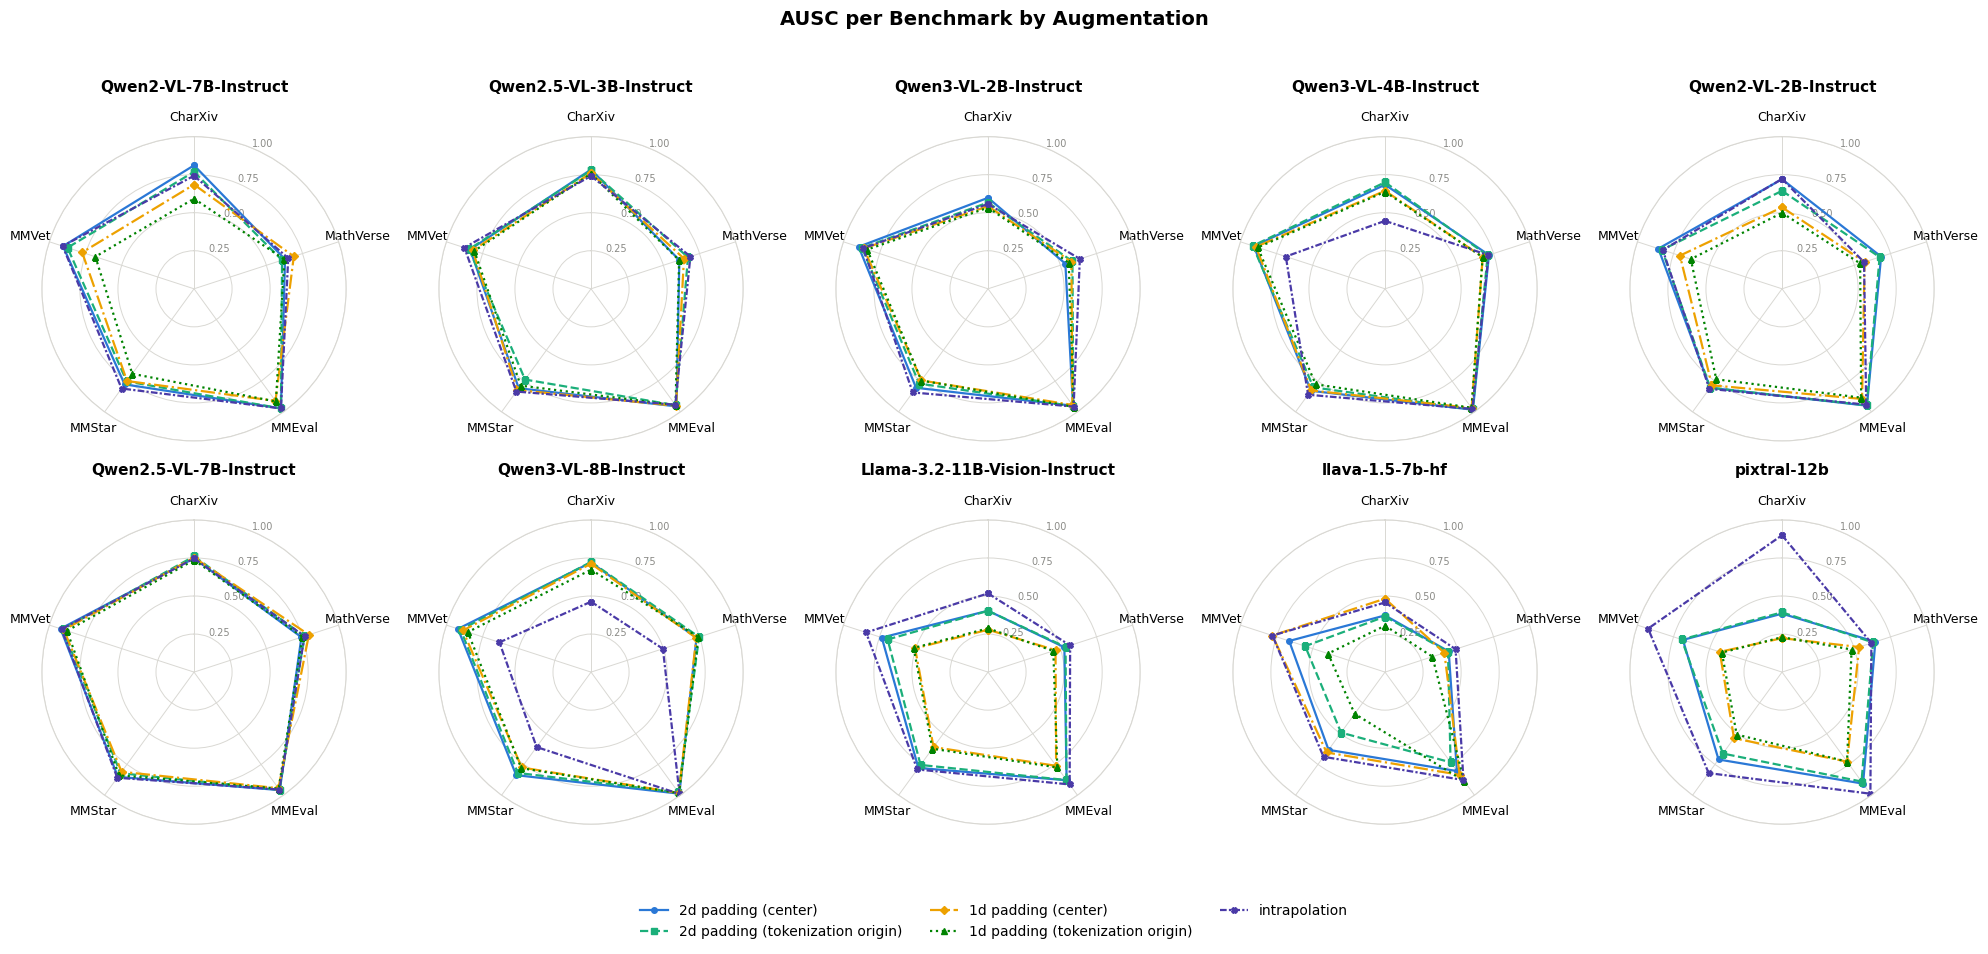

In [73]:
def plot_radar_per_model(final_table_per_benchmark, benchmarks, models, metric="AUSC", augmentations=None):
    if augmentations is None:
        augmentations = list(dict.fromkeys(final_table_per_benchmark["augmentation"]))

    color_map = {
        "2d padding (center)": "#2a78d6",
        "2d padding (tokenization origin)": "#1baf7a",
        "1d padding (center)": "#eda100",
        "1d padding (tokenization origin)": "#008300",
        "intrapolation": "#4a3aa7",
    }
    linestyle_map = {
        "2d padding (center)": "-",
        "2d padding (tokenization origin)": "--",
        "1d padding (center)": "-.",
        "1d padding (tokenization origin)": ":",
        "intrapolation": (0, (3, 1, 1, 1)),
    }
    marker_map = {
        "2d padding (center)": "o",
        "2d padding (tokenization origin)": "s",
        "1d padding (center)": "D",
        "1d padding (tokenization origin)": "^",
        "intrapolation": "X",
    }

    n_vars = len(benchmarks)
    angles = np.linspace(0, 2 * np.pi, n_vars, endpoint=False).tolist()
    angles += angles[:1]

    n_models = len(models)
    ncols = 5
    nrows = int(np.ceil(n_models / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.4 * nrows), subplot_kw=dict(polar=True))
    axes = np.atleast_1d(axes).reshape(-1)

    i = 0
    for i, model_name in enumerate(models):
        ax = axes[i]
        m_df = final_table_per_benchmark[final_table_per_benchmark["model"] == model_name]

        for aug in augmentations:
            aug_row = m_df[m_df["augmentation"] == aug]
            if aug_row.empty:
                continue
            values = aug_row.set_index("benchmark")[metric].reindex(benchmarks).tolist()
            values += values[:1]

            ax.plot(
                angles, values,
                color=color_map[aug], linestyle=linestyle_map[aug],
                linewidth=1.6, marker=marker_map[aug], markersize=4,
                label=aug,
            )

        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(benchmarks, fontsize=9)
        ax.set_ylim(0, 1)
        ax.set_yticks([0.25, 0.5, 0.75, 1.0])
        ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=7, color="#8a8a86")
        ax.grid(color="#d9d8d3", linewidth=0.7)
        ax.spines['polar'].set_color("#d9d8d3")
        ax.set_title(model_name, fontsize=11, fontweight='bold', pad=14)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05), fontsize=10, frameon=False)

    fig.suptitle(f"{metric} per Benchmark by Augmentation", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()

plot_radar_per_model(final_table_per_benchmark, benchmarks, models, metric="AUSC")


### PVS spiderweb per model, all augmentations overlaid

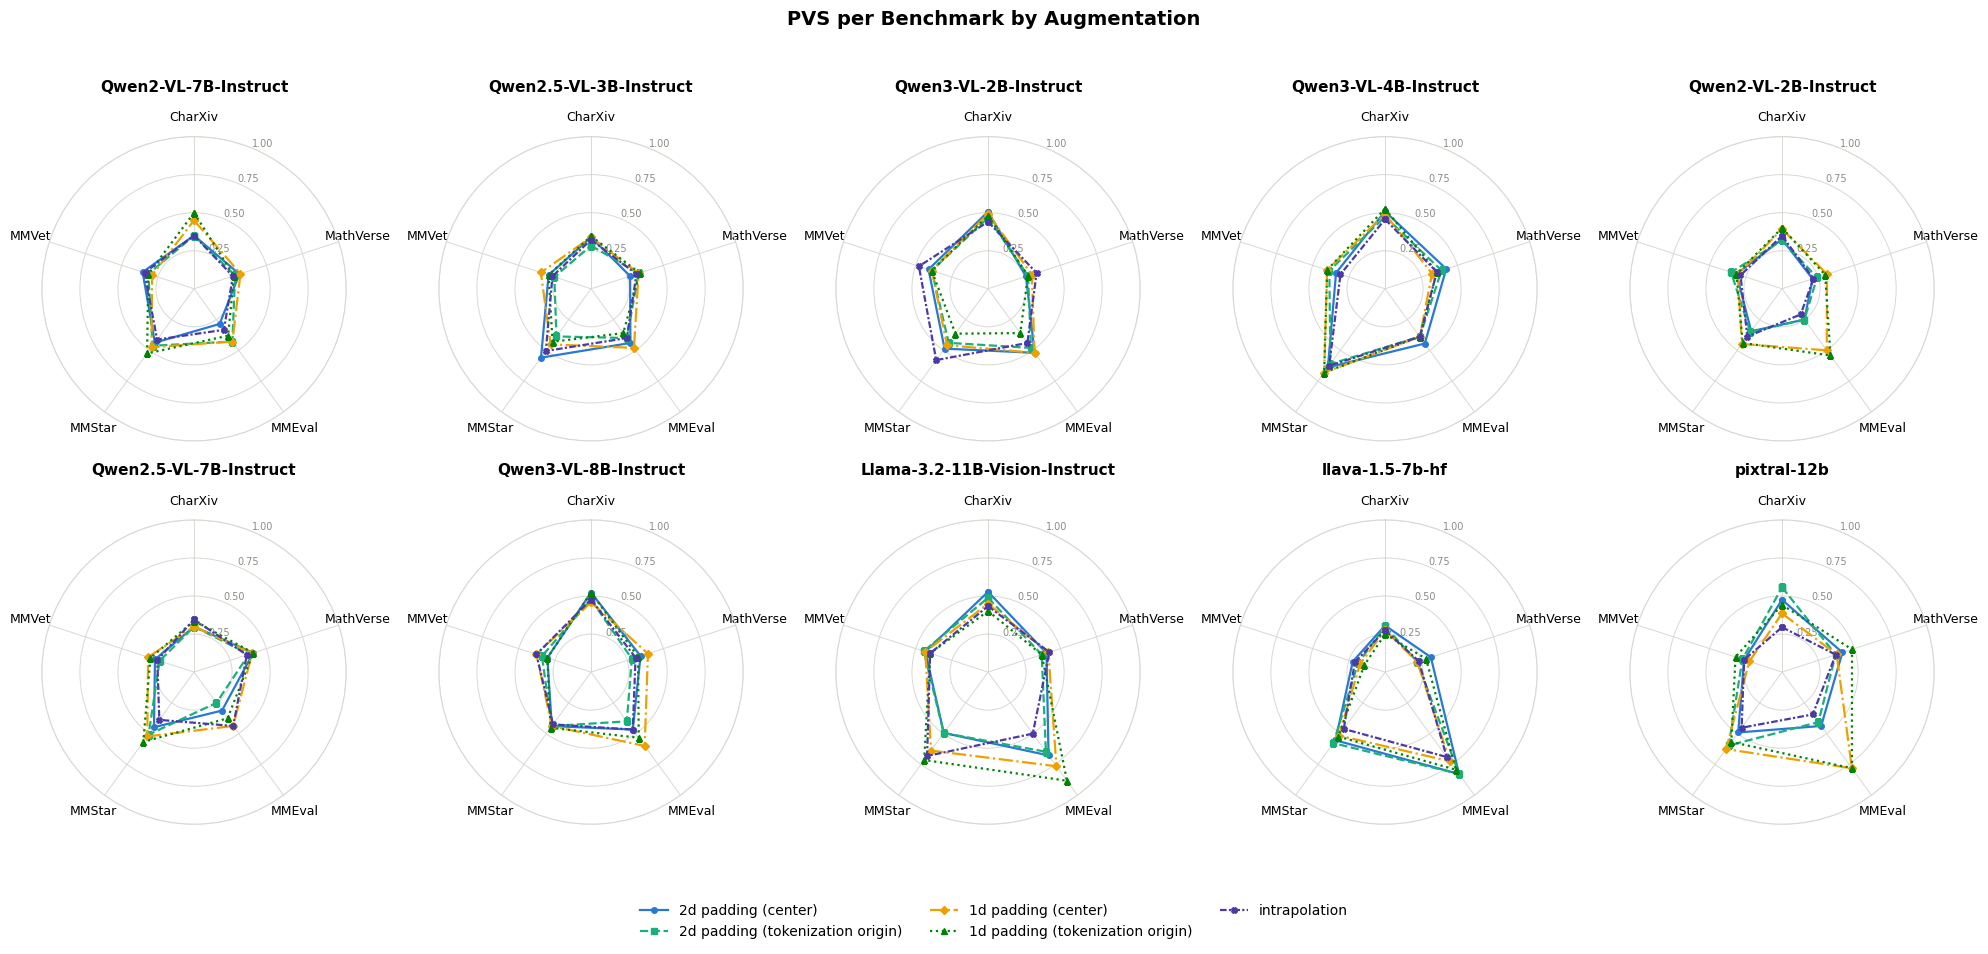

In [74]:
plot_radar_per_model(final_table_per_benchmark, benchmarks, models, metric="PVS")


### Distribution of cases

In [75]:
df_combined = pd.concat([df_combined1, df_combined2, df_combined3, df_combined4, df_combined5], ignore_index=True)

# Define score columns
score_cols = ['score0', 'score0.5', 'score1', 'score2', 'score3', 'score4', 'score5']

# Group by (id, benchmark, model) and check conditions for each unique pair
conditions = df_combined.groupby(['id', 'benchmark', 'model']).apply(lambda x: pd.Series({
    'all_ones': ((x[score_cols] == 1).all(axis=1)).all(),
    'all_zeros': ((x[score_cols] == 0).all(axis=1)).all(),
    'mixed': (((x[score_cols] == 1).any(axis=1)) & ((x[score_cols] == 0).any(axis=1))).any(),
    'originally_correct': (x['score0'] == 1).all()
})).reset_index()

# Split the mixed subset by whether the original (unaugmented) score was correct or wrong
conditions['mixed_originally_correct'] = conditions['mixed'] & conditions['originally_correct']
conditions['mixed_originally_wrong'] = conditions['mixed'] & ~conditions['originally_correct']

# Group by model and count unique (id, benchmark) pairs
results = conditions.groupby('model').agg({
    'all_ones': 'sum',
    'all_zeros': 'sum',
    'mixed_originally_correct': 'sum',
    'mixed_originally_wrong': 'sum'
}).rename(columns={
    'all_ones': 'All scores = 1',
    'all_zeros': 'All scores = 0',
    'mixed_originally_correct': 'Mixed (originally correct)',
    'mixed_originally_wrong': 'Mixed (originally wrong)'
}).reset_index()

results

,model,All scores = 1,All scores = 0,Mixed (originally correct),Mixed (originally wrong)
0,Llama-3.2-11B-Vision-Instruct,40,112,452,381
1,Qwen2-VL-2B-Instruct,148,237,293,307
2,Qwen2-VL-7B-Instruct,200,169,354,262
3,Qwen2.5-VL-3B-Instruct,237,192,291,265
4,Qwen2.5-VL-7B-Instruct,314,159,281,231
5,Qwen3-VL-2B-Instruct,209,187,250,339
6,Qwen3-VL-4B-Instruct,214,115,377,279
7,Qwen3-VL-8B-Instruct,174,133,444,234
8,llava-1.5-7b-hf,39,241,308,397
9,pixtral-12b,62,142,430,351


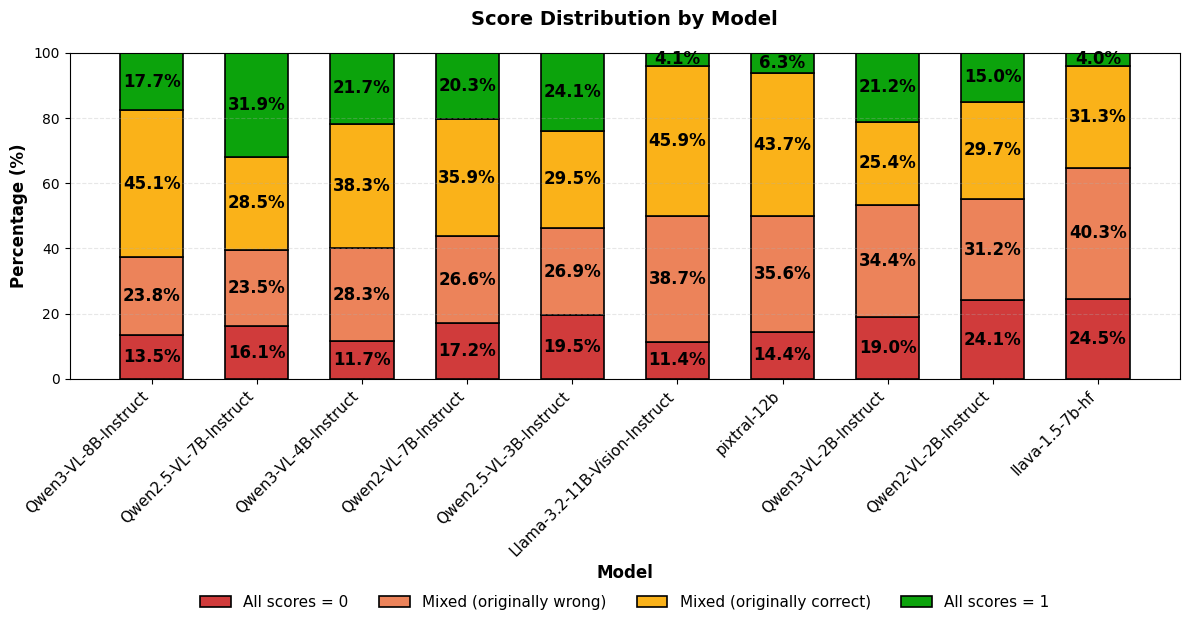

In [76]:
# Calculate percentages
results['total'] = results['All scores = 1'] + results['All scores = 0'] + results['Mixed (originally correct)'] + results['Mixed (originally wrong)']
results['% All 1s'] = (results['All scores = 1'] / results['total'] * 100)
results['% All 0s'] = (results['All scores = 0'] / results['total'] * 100)
results['% Mixed (originally correct)'] = (results['Mixed (originally correct)'] / results['total'] * 100)
results['% Mixed (originally wrong)'] = (results['Mixed (originally wrong)'] / results['total'] * 100)

# Sort by original (unaugmented) accuracy, highest to lowest
original_accuracy = df_combined.groupby('model')['score0'].mean()
results['original_accuracy'] = results['model'].map(original_accuracy)
results = results.sort_values('original_accuracy', ascending=False).reset_index(drop=True)

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Data for stacked bar
categories = results['model'].values
all_zeros = results['% All 0s'].values
mixed_wrong = results['% Mixed (originally wrong)'].values
mixed_correct = results['% Mixed (originally correct)'].values
all_ones = results['% All 1s'].values

# Status palette: these classes encode good/bad (pass/fail robustness), not arbitrary series identity
COLOR_CRITICAL = '#d03b3b'  # All scores = 0
COLOR_SERIOUS = '#ec835a'   # Mixed, originally wrong
COLOR_WARNING = '#fab219'   # Mixed, originally correct
COLOR_GOOD = '#0ca30c'      # All scores = 1

# Create bars
x = np.arange(len(categories))
width = 0.6

p1 = ax.bar(x, all_zeros, width, label='All scores = 0', color=COLOR_CRITICAL, edgecolor='black', linewidth=1.2)
p2 = ax.bar(x, mixed_wrong, width, bottom=all_zeros, label='Mixed (originally wrong)', color=COLOR_SERIOUS, edgecolor='black', linewidth=1.2)
p3 = ax.bar(x, mixed_correct, width, bottom=all_zeros + mixed_wrong, label='Mixed (originally correct)', color=COLOR_WARNING, edgecolor='black', linewidth=1.2)
p4 = ax.bar(x, all_ones, width, bottom=all_zeros + mixed_wrong + mixed_correct, label='All scores = 1', color=COLOR_GOOD, edgecolor='black', linewidth=1.2)

# Customize plot
ax.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Model', fontsize=12, fontweight='bold')
ax.set_title('Score Distribution by Model', fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11, rotation=45, ha="right")
ax.set_ylim(0, 100)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.62), ncol=4, fontsize=11, frameon=False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add percentage labels on each segment
bottoms = np.zeros(len(categories))
for seg in (all_zeros, mixed_wrong, mixed_correct, all_ones):
    for i, v in enumerate(seg):
        if v > 3:
            ax.text(i, bottoms[i] + v / 2, f'{v:.1f}%', ha='center', va='center', fontweight='bold', fontsize=12)
    bottoms += seg

plt.tight_layout()
plt.subplots_adjust(bottom=0.52)
plt.show()

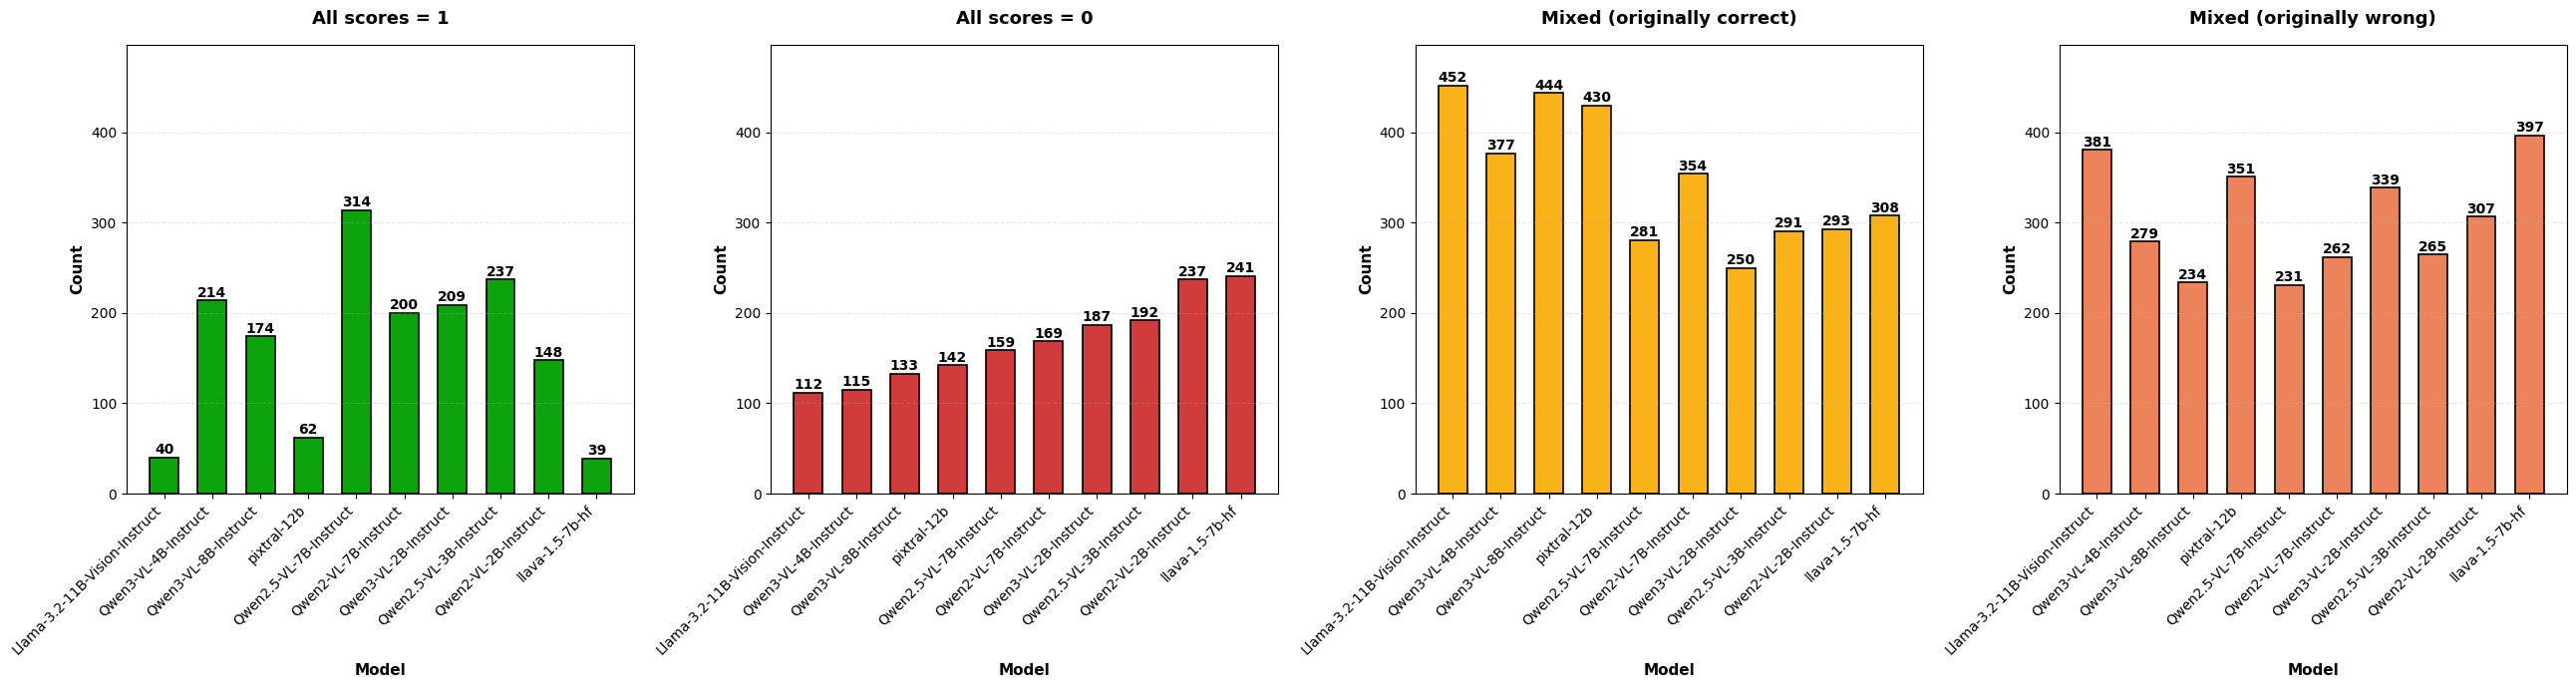

In [77]:
# Calculate percentages
results['total'] = results['All scores = 1'] + results['All scores = 0'] + results['Mixed (originally correct)'] + results['Mixed (originally wrong)']
results['% All 1s'] = (results['All scores = 1'] / results['total'] * 100)
results['% All 0s'] = (results['All scores = 0'] / results['total'] * 100)
results['% Mixed (originally correct)'] = (results['Mixed (originally correct)'] / results['total'] * 100)
results['% Mixed (originally wrong)'] = (results['Mixed (originally wrong)'] / results['total'] * 100)

# Sort by All scores = 0 in ascending order
results = results.sort_values('All scores = 0', ascending=True).reset_index(drop=True)

# Create figure with 4 subplots
fig, axes = plt.subplots(1, 4, figsize=(26, 7))

categories = results['model'].values
x = np.arange(len(categories))
width = 0.6

# Status palette: these classes encode good/bad (pass/fail robustness), matches the stacked bar above
panels = [
    ('All scores = 1', '#0ca30c'),
    ('All scores = 0', '#d03b3b'),
    ('Mixed (originally correct)', '#fab219'),
    ('Mixed (originally wrong)', '#ec835a'),
]

# Find max value across all four datasets
y_max = max(results[col].max() for col, _ in panels) * 1.1  # Add 10% padding

for ax, (col, color) in zip(axes, panels):
    ax.bar(x, results[col], width, color=color, edgecolor='black', linewidth=1.2)
    ax.set_title(col, fontsize=13, fontweight='bold', pad=15)
    ax.set_ylabel('Count', fontsize=11, fontweight='bold')
    ax.set_xlabel('Model', fontsize=11, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=45, ha='right', fontsize=10)
    ax.set_ylim(0, y_max)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

    # Add value labels
    for i, v in enumerate(results[col]):
        ax.text(i, v + 0.5, str(int(v)), ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# Stratified by original image size

### Original image sizes per benchmark

In [78]:
import random
from datasets import load_dataset

IMAGE_SIZE_CACHE = "image_sizes.json"

# (dataset, config, split, id_field) for each benchmark's ORIGINAL images,
# matching the sampling in src/benchmarks.py exactly so ids line up with df_combined
BENCHMARK_SPECS = {
    "MMVet": ("whyu/mm-vet", None, "test", "id"),
    "MMEval": ("darkyarding/MME", None, "test", "question_id"),
    "MathVerse": ("AI4Math/MathVerse", "testmini", "testmini", "sample_index"),
    "MMStar": ("Lin-Chen/MMStar", None, "val", "index"),
    "CharXiv": ("princeton-nlp/CharXiv", None, "validation", "original_figure_path"),
}

def fetch_image_sizes(seed=42, sample_size=200):
    rows = []
    for benchmark, (dataset_name, config, split, id_field) in BENCHMARK_SPECS.items():
        full_dataset = load_dataset(dataset_name, config)[split] if config else load_dataset(dataset_name)[split]

        random.seed(seed)
        indices = list(range(len(full_dataset)))
        sampled_indices = random.sample(indices, min(sample_size, len(full_dataset)))

        for sample in full_dataset.select(sampled_indices):
            width, height = sample["image"].size
            rows.append({"benchmark": benchmark, "id": sample[id_field], "width": width, "height": height})

    return pd.DataFrame(rows)

if os.path.exists(IMAGE_SIZE_CACHE):
    image_sizes = pd.read_json(IMAGE_SIZE_CACHE)
else:
    image_sizes = fetch_image_sizes()
    image_sizes.to_json(IMAGE_SIZE_CACHE, orient="records")

image_sizes["area"] = image_sizes["width"] * image_sizes["height"]
image_sizes.groupby("benchmark")["area"].describe()

,count,mean,std,min,25%,50%,75%,max
benchmark,,,,,,,,
CharXiv,200.0,697116.230,2.079720e+05,164864.0,522753.0,708096.0,854272.00,1048576.0
MMEval,200.0,550230.065,5.253965e+05,15747.0,188270.0,393216.0,718500.00,3913400.0
MMStar,200.0,264447.890,5.030109e+05,7524.0,98304.0,175360.0,223254.50,5219840.0
MMVet,200.0,1105728.735,1.831828e+06,32940.0,257895.0,568000.0,1327981.25,17471147.0
MathVerse,200.0,495908.205,9.760060e+05,4410.0,59191.5,174715.0,380026.50,6868643.0


### Discard outliers and bucket into size groups

In [79]:
# Discard extreme outliers with the 1.5*IQR rule on log-area (robust to the natural
# heavy right skew of image sizes), then split the rest into 3 equal-sized groups
log_area = np.log10(image_sizes["area"])
q1, q3 = log_area.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

is_outlier = (log_area < lower) | (log_area > upper)
print(f"Discarding {is_outlier.sum()} / {len(image_sizes)} images as size outliers "
      f"(area outside [{10**lower:,.0f}, {10**upper:,.0f}] px^2)")

SIZE_GROUPS = ["Small", "Medium", "Large"]
image_sizes_clean = image_sizes.loc[~is_outlier].copy()
image_sizes_clean["size_group"] = pd.qcut(image_sizes_clean["area"], len(SIZE_GROUPS), labels=SIZE_GROUPS)

image_sizes_clean.groupby("size_group", observed=True)["area"].agg(["count", "min", "max"])

Discarding 40 / 1000 images as size outliers (area outside [17,209, 7,406,314] px^2)


,count,min,max
size_group,,,
Small,320,17738,220459
Medium,320,222750,643568
Large,320,649605,6868643


### Stratified AUSC / PVS by size group

In [80]:
size_lookup = image_sizes_clean[["benchmark", "id", "size_group"]]

all_results_by_size = []

for aug_name, aug_df in augmentation_dfs.items():
    sized_df = aug_df.merge(size_lookup, on=["benchmark", "id"], how="inner")  # drops outlier / unmatched images

    for size_group in SIZE_GROUPS:
        group_df = sized_df[sized_df["size_group"] == size_group]

        metrics = compute_metrics(df=group_df, models=models, fields=fields)

        summary = metrics[["model", "A0", "AUSC", "PVS"]].copy()
        summary["augmentation"] = aug_name
        summary["size_group"] = size_group

        all_results_by_size.append(summary)

final_table_by_size = pd.concat(all_results_by_size, ignore_index=True)
final_table_by_size

,model,A0,AUSC,PVS,augmentation,size_group
0,Qwen2-VL-7B-Instruct,0.562500,0.797778,0.407143,2d padding (center),Small
1,Qwen2.5-VL-3B-Instruct,0.528125,0.821598,0.443709,2d padding (center),Small
2,Qwen3-VL-2B-Instruct,0.487500,0.813141,0.402439,2d padding (center),Small
3,Qwen3-VL-4B-Instruct,0.631250,0.857178,0.533898,2d padding (center),Small
4,Qwen2-VL-2B-Instruct,0.418750,0.799254,0.290323,2d padding (center),Small
...,...,...,...,...,...,...
145,Qwen2.5-VL-7B-Instruct,0.603125,0.848705,0.307087,intrapolation,Large
146,Qwen3-VL-8B-Instruct,0.628125,0.665423,0.420168,intrapolation,Large
147,Llama-3.2-11B-Vision-Instruct,0.465625,0.755034,0.456140,intrapolation,Large
148,llava-1.5-7b-hf,0.337500,0.751852,0.254717,intrapolation,Large


In [81]:
paper_table_by_size = final_table_by_size.pivot(
    index="model",
    columns=["size_group", "augmentation"],
    values=["AUSC", "PVS"]
)
paper_table_by_size

AUSC                      \
size_group                                  Small              Medium   
augmentation                  2d padding (center) 2d padding (center)   
model                                                                   
Llama-3.2-11B-Vision-Instruct            0.789286            0.712500   
Qwen2-VL-2B-Instruct                     0.799254            0.882903   
Qwen2-VL-7B-Instruct                     0.797778            0.875676   
Qwen2.5-VL-3B-Instruct                   0.821598            0.828022   
Qwen2.5-VL-7B-Instruct                   0.870149            0.888693   
Qwen3-VL-2B-Instruct                     0.813141            0.844444   
Qwen3-VL-4B-Instruct                     0.857178            0.854737   
Qwen3-VL-8B-Instruct                     0.868293            0.866176   
llava-1.5-7b-hf                          0.680165            0.671429   
pixtral-12b                              0.733766            0.740698   

                                                   \
size_group                                  Large   
augmentation                  2d padding (center)   
model                                               
Llama-3.2-11B-Vision-Instruct            0.675839   
Qwen2-VL-2B-Instruct                     0.846732   
Qwen2-VL-7B-Instruct                     0.897541   
Qwen2.5-VL-3B-Instruct                   0.867429   
Qwen2.5-VL-7B-Instruct                   0.858549   
Qwen3-VL-2B-Instruct                     0.849000   
Qwen3-VL-4B-Instruct                     0.860567   
Qwen3-VL-8B-Instruct                     0.875871   
llava-1.5-7b-hf                          0.709259   
pixtral-12b                              0.665089   

                                                                \
size_group                                               Small   
augmentation                  2d padding (tokenization origin)   
model                                                            
Llama-3.2-11B-Vision-Instruct                         0.760417   
Qwen2-VL-2B-Instruct                                  0.805224   
Qwen2-VL-7B-Instruct                                  0.763333   
Qwen2.5-VL-3B-Instruct                                0.808580   
Qwen2.5-VL-7B-Instruct                                0.862438   
Qwen3-VL-2B-Instruct                                  0.813782   
Qwen3-VL-4B-Instruct                                  0.841089   
Qwen3-VL-8B-Instruct                                  0.858780   
llava-1.5-7b-hf                                       0.574380   
pixtral-12b                                           0.687662   

                                                                \
size_group                                              Medium   
augmentation                  2d padding (tokenization origin)   
model                                                            
Llama-3.2-11B-Vision-Instruct                         0.714244   
Qwen2-VL-2B-Instruct                                  0.859677   
Qwen2-VL-7B-Instruct                                  0.875946   
Qwen2.5-VL-3B-Instruct                                0.818407   
Qwen2.5-VL-7B-Instruct                                0.880653   
Qwen3-VL-2B-Instruct                                  0.844118   
Qwen3-VL-4B-Instruct                                  0.857895   
Qwen3-VL-8B-Instruct                                  0.883578   
llava-1.5-7b-hf                                       0.624603   
pixtral-12b                                           0.736337   

                                                                \
size_group                                               Large   
augmentation                  2d padding (tokenization origin)   
model                                                            
Llama-3.2-11B-Vision-Instruct                         0.660738   
Qwen2-VL-2B-Instruct                                  0.812092   
Qwen2-VL-7B-Instruct             

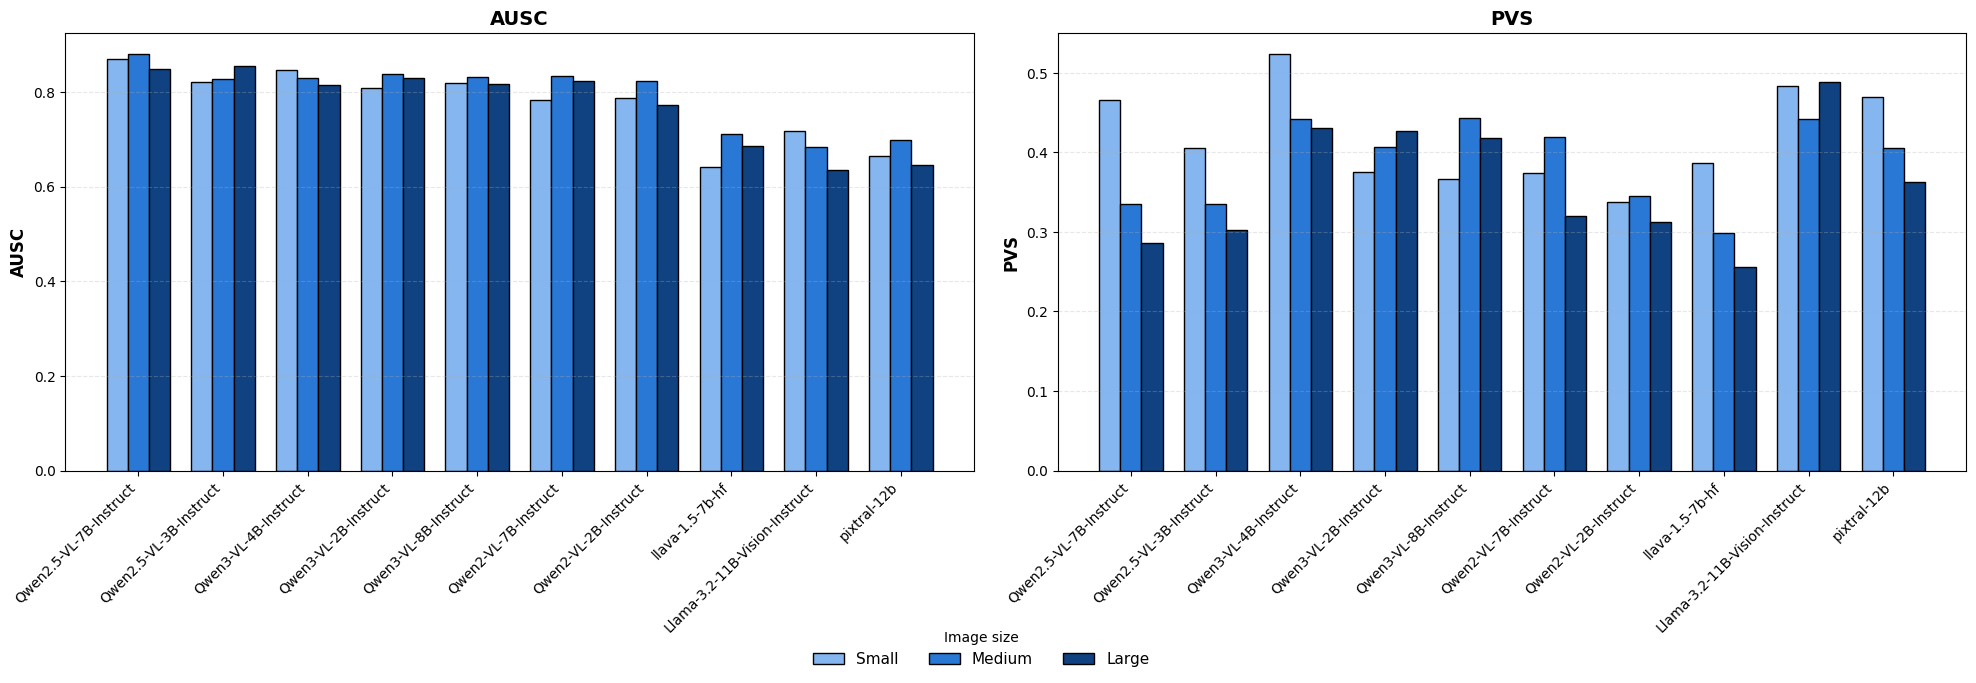

In [82]:
# Average across augmentations to summarize robustness by image size
size_summary = (
    final_table_by_size
    .groupby(["model", "size_group"], observed=True)[["AUSC", "PVS"]]
    .mean()
    .reset_index()
)

model_order = size_summary.groupby("model")["AUSC"].mean().sort_values(ascending=False).index

# Ordinal palette: Small -> Medium -> Large is a meaningful order, so one hue, light to dark
SIZE_GROUP_COLORS = {"Small": "#86b6ef", "Medium": "#2a78d6", "Large": "#104281"}

ausc_wide = size_summary.pivot(index="model", columns="size_group", values="AUSC").loc[model_order]
pvs_wide = size_summary.pivot(index="model", columns="size_group", values="PVS").loc[model_order]

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
x = np.arange(len(model_order))
width = 0.25

for ax, metric_name, wide in zip(axes, ["AUSC", "PVS"], [ausc_wide, pvs_wide]):
    for i, size_group in enumerate(SIZE_GROUPS):
        ax.bar(x + (i - 1) * width, wide[size_group], width, label=size_group,
               color=SIZE_GROUP_COLORS[size_group], edgecolor='black', linewidth=1.0)

    ax.set_title(metric_name, fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel(metric_name, fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.3, linestyle='--')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Image size", loc='lower center', bbox_to_anchor=(0.5, 0.02), ncol=3, frameon=False, fontsize=11)

plt.tight_layout()
plt.subplots_adjust(bottom=0.32)
plt.show()

# Interpolation

In [83]:
scales = [1.5,2,3,4]

# Scale

In [84]:
scales = [1.5,2,3,4,5,6]

In [85]:
# aggregate sampled results for multiple benchmarks
def generate_dataframe(results_dir, benchmark, model, scales, position=""):
    path = os.path.join(
            "evaluated1/results0",
            f'{model}/{benchmark}/{benchmark}_{model}_0.json'
        )
    
    with open(path, "r") as f:
        data = json.load(f)
        
    df = pd.DataFrame(data)
    df = df.rename(columns={"score": "score1"}) # rename score into score0

    # generate a dataframe
    for af in scales:
        path = os.path.join(
            results_dir,
            f'{model}/{benchmark}/{benchmark}_{model}_{af}.json'
        )
        with open(path, "r") as f:
            data = json.load(f)
            
        df_field = pd.DataFrame(data).filter(items=['id', 'score'])
        df_field.columns=['id', f"score{af}"]
        df = df.merge(df_field, on='id', how='left')

    
    for af in [1,1.5,2,3,4]:
        df[f"score{af}"] = pd.to_numeric(df[f"score{af}"], errors='coerce') # replace non numeric scores with NaN
        df[f"score{af}"] = df[f"score{af}"].fillna(0) # fill NaN scores with 0
        df[f"score{af}"] = df[f"score{af}"].apply(lambda x: 0 if x > 1 else x) # replace all scores > 1 with 0
        df[f"score{af}"] = df[f"score{af}"].apply(lambda x: 1 if x >= 0.7 else 0) # convert scores to binary (1 if score >= 0.7 else 0)

    return df

def aggregate_dataframe(df):
    # for each id in column "id", calculate the result of multiplication of the scores corresponding to this id
    # and store it in a new column "agg_score{af}"  for each af in fields
    agg_df = df.groupby('id').agg({col: 'max' for col in df.columns if col.startswith('score')}).reset_index()
    return agg_df

def plot_model_accuracies(df):
    plt.figure(figsize=(11, 6))
    
    fields = [col for col in df.columns if col not in ["model", "family"] ]
    
    # Extract families dynamically
    df["family"] = df["model"].apply(extract_family)
    families = sorted(df["family"].unique())
    
    # Assign markers per family (scalable)
    marker_list = ['o', 's', 'D', '^', 'v', 'P', 'X', '*', '<', '>']
    family_to_marker = {
        fam: marker_list[i % len(marker_list)]
        for i, fam in enumerate(families)
    }
    
    # Colors per model
    colors = plt.cm.tab20.colors
    
    for i, (_, row) in enumerate(df.iterrows()):
        plt.plot(
            fields,
            row[fields],
            label=row["model"],
            color=colors[i % len(colors)],
            marker=family_to_marker[row["family"]],
            linewidth=2,
            markersize=6
        )
    
    # Labels
    plt.xlabel("Fields", fontsize=12)
    plt.ylabel("Accuracy", fontsize=12)
    plt.title("Model Performance Across Fields", fontsize=14)
    
    # Grid
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
    
    # X ticks
    plt.xticks(rotation=45)
    
    # Legend (models)
    plt.legend(
        title="Model",
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        fontsize=9
    )
    
    plt.tight_layout()
    plt.show()

In [86]:
benchmarks = [
    "CharXiv",
    "MathVerse",
    "MMEval",
    "MMStar",
    "MMVet"
]

models = [
 #'Qwen2-VL-72B-Instruct',
 #'Qwen2.5-VL-32B-Instruct',
 'Qwen2-VL-7B-Instruct',
 'Qwen2.5-VL-3B-Instruct',
 'Qwen3-VL-2B-Instruct',
 'Qwen3-VL-4B-Instruct',
 'Qwen2-VL-2B-Instruct',
 #'Qwen2.5-VL-72B-Instruct',
 'Qwen2.5-VL-7B-Instruct',
# 'Qwen3-VL-32B-Instruct',
 'Qwen3-VL-8B-Instruct',
 'Llama-3.2-11B-Vision-Instruct',
 'llava-1.5-7b-hf',
 'pixtral-12b',
 #"gpt-5-mini"
 ]

In [87]:
#model = models[0]
df_combined = pd.DataFrame()
accuracies = pd.DataFrame()
accuracies_b = pd.DataFrame()

for model in models:
    for benchmark in benchmarks:
        df = generate_dataframe(
            results_dir = "evaluated/results_interpolation",
            benchmark = benchmark,
            model = model,
            scales = scales
        )
        df = aggregate_dataframe(df)
        df["benchmark"] = benchmark
        df["model"] = model

        # Compute accuracy at each field per benchmark
        accuracy_b = calculate_accuracies(df, [1,1.5,2,3,4])
        accuracy_b['benchmark'] = benchmark
        accuracy_b['model'] = model
        accuracies_b = pd.concat([accuracies_b, accuracy_b])

        # combine all benchmarks
        df_combined = pd.concat([df_combined, df])

    # Compute accuracy at each field
    accuracy_m = calculate_accuracies(df_combined, [1,1.5,2,3,4])
    accuracy_m['model'] = model
    accuracies = pd.concat([accuracies, accuracy_m])

In [88]:
accuracies

,score1,score1.5,score2,score3,score4,model
0,0.562437,0.517766,0.497462,0.488325,0.490355,Qwen2-VL-7B-Instruct
0,0.549239,0.500000,0.480203,0.471066,0.472081,Qwen2.5-VL-3B-Instruct
0,0.521489,0.475127,0.465651,0.464975,0.459222,Qwen3-VL-2B-Instruct
0,0.541117,0.498731,0.494416,0.491878,0.486041,Qwen3-VL-4B-Instruct
0,0.522437,0.479797,0.472487,0.471269,0.467614,Qwen2-VL-2B-Instruct
0,0.536041,0.490017,0.486633,0.480203,0.475465,Qwen2.5-VL-7B-Instruct
0,0.549094,0.503263,0.500798,0.496157,0.490790,Qwen3-VL-8B-Instruct
0,0.542893,0.491117,0.490102,0.485152,0.483249,Llama-3.2-11B-Vision-Instruct
0,0.521715,0.468359,0.467569,0.463508,0.462155,llava-1.5-7b-hf
0,0.519492,0.470761,0.468832,0.465685,0.464873,pixtral-12b


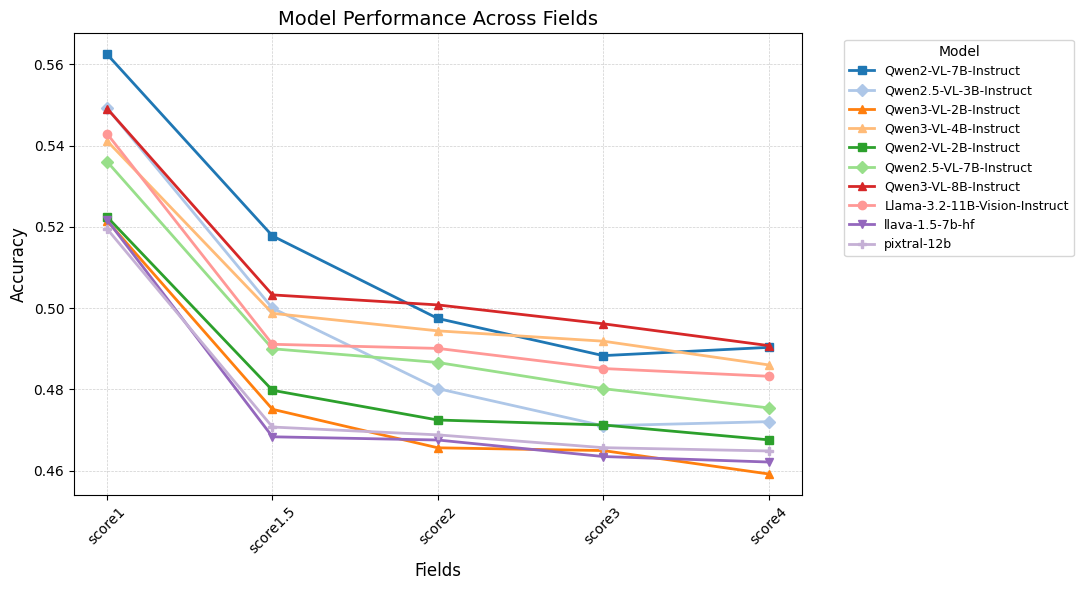

In [89]:
plot_model_accuracies(accuracies)

In [90]:
fields = [1,1.5,2,3,4]

ausc_pvs = pd.DataFrame()
rows = []

for model in models:
    m_df = df_combined[df_combined['model'] == model]
    
    m_correct = m_df[m_df["score1"] == 1]
    m_wrong   = m_df[m_df["score1"] == 0]

    # Handle edge cases (avoid division by zero)
    if len(m_correct) > 0:
        decay = m_correct[[f"score{af}" for af in fields]].mean()
    else:
        decay = pd.Series([0]*len(fields), index=[f"score{af}" for af in fields])

    if len(m_wrong) > 0:
        recovery = m_wrong[[f"score{af}" for af in fields]].mean()
        overall_recovery = (m_wrong[[f"score{af}" for af in fields]] == 1).any(axis=1).mean()
    else:
        recovery = pd.Series([0]*len(fields), index=[f"score{af}" for af in fields])

    # Rename indices → desired column names
    decay.index = [f"decay{af}" for af in fields]
    recovery.index = [f"recovery{af}" for af in fields]

    # Combine into one row
    row = pd.concat([decay, recovery])
    row["overall_recovery"] = overall_recovery
    row["model"] = model

    rows.append(row)

# Build final DataFrame
ausc_pvs = pd.DataFrame(rows).reset_index(drop=True)

In [91]:
ausc_pvs

,decay1,decay1.5,decay2,decay3,decay4,recovery1,recovery1.5,recovery2,recovery3,recovery4,overall_recovery,model
0,1.0,0.826715,0.803249,0.761733,0.768953,0.0,0.120650,0.104408,0.136891,0.132251,0.232019,Qwen2-VL-7B-Instruct
1,1.0,0.789773,0.768939,0.751894,0.729167,0.0,0.126915,0.109409,0.109409,0.135667,0.247265,Qwen2.5-VL-3B-Instruct
2,1.0,0.775599,0.784314,0.777778,0.766885,0.0,0.119772,0.133080,0.169202,0.142586,0.334601,Qwen3-VL-2B-Instruct
3,1.0,0.810491,0.820643,0.805415,0.802030,0.0,0.208122,0.220812,0.223350,0.213198,0.428934,Qwen3-VL-4B-Instruct
4,1.0,0.786848,0.739229,0.743764,0.746032,0.0,0.093750,0.097426,0.101103,0.108456,0.226103,Qwen2-VL-2B-Instruct
5,1.0,0.830252,0.833613,0.783193,0.773109,0.0,0.100000,0.135897,0.130769,0.120513,0.251282,Qwen2.5-VL-7B-Instruct
6,1.0,0.812298,0.812298,0.815534,0.810680,0.0,0.196185,0.204360,0.215259,0.198910,0.414169,Qwen3-VL-8B-Instruct
7,1.0,0.658537,0.693089,0.662602,0.697154,0.0,0.154158,0.137931,0.154158,0.164300,0.354970,Llama-3.2-11B-Vision-Instruct
8,1.0,0.697406,0.682997,0.703170,0.706052,0.0,0.062696,0.072100,0.065831,0.068966,0.194357,llava-1.5-7b-hf
9,1.0,0.837398,0.813008,0.817073,0.821138,0.0,0.148073,0.148073,0.154158,0.158215,0.265720,pixtral-12b


In [92]:
def compute_decay_ausc(df, fields):
    decay_cols = [f"decay{af}" for af in fields]
    x = np.array(fields)
    dx = np.diff(x)

    def compute_ausc(row):
        y = row[decay_cols].values.astype(float)
        area = np.sum(dx * (y[:-1] + y[1:]) / 2)
        return area / np.sum(dx)

    df = df.copy()
    df["AUSC"] = df.apply(compute_ausc, axis=1)
    return df


In [93]:
compute_decay_ausc(ausc_pvs, fields)

,decay1,decay1.5,decay2,decay3,decay4,recovery1,recovery1.5,recovery2,recovery3,recovery4,overall_recovery,model,AUSC
0,1.0,0.826715,0.803249,0.761733,0.768953,0.0,0.120650,0.104408,0.136891,0.132251,0.232019,Qwen2-VL-7B-Instruct,0.804001
1,1.0,0.789773,0.768939,0.751894,0.729167,0.0,0.126915,0.109409,0.109409,0.135667,0.247265,Qwen2.5-VL-3B-Instruct,0.779356
2,1.0,0.775599,0.784314,0.777778,0.766885,0.0,0.119772,0.133080,0.169202,0.142586,0.334601,Qwen3-VL-2B-Instruct,0.795752
3,1.0,0.810491,0.820643,0.805415,0.802030,0.0,0.208122,0.220812,0.223350,0.213198,0.428934,Qwen3-VL-4B-Instruct,0.825719
4,1.0,0.786848,0.739229,0.743764,0.746032,0.0,0.093750,0.097426,0.101103,0.108456,0.226103,Qwen2-VL-2B-Instruct,0.771542
5,1.0,0.830252,0.833613,0.783193,0.773109,0.0,0.100000,0.135897,0.130769,0.120513,0.251282,Qwen2.5-VL-7B-Instruct,0.820028
6,1.0,0.812298,0.812298,0.815534,0.810680,0.0,0.196185,0.204360,0.215259,0.198910,0.414169,Qwen3-VL-8B-Instruct,0.828749
7,1.0,0.658537,0.693089,0.662602,0.697154,0.0,0.154158,0.137931,0.154158,0.164300,0.354970,Llama-3.2-11B-Vision-Instruct,0.703421
8,1.0,0.697406,0.682997,0.703170,0.706052,0.0,0.062696,0.072100,0.065831,0.068966,0.194357,llava-1.5-7b-hf,0.722382
9,1.0,0.837398,0.813008,0.817073,0.821138,0.0,0.148073,0.148073,0.154158,0.158215,0.265720,pixtral-12b,0.835366
